# Tutorial 8: Building a Transformer that Sorts Strings

Course: **Applied Deep Learning (ECE1553) - FALL 2026**
Instructor: **Dr. Ali Breyhi**
Tutorial: **Saleh Tabatabaei**

We will build the Transformer from *Attention Is All You Need* **from scratch**, following the structure and class names of the
[Annotated Transformer](https://nlp.seas.harvard.edu/annotated-transformer/), and train it on a classic algorithms problem:
**String Sort** ([Algorithms 4/e, §5.1](https://algs4.cs.princeton.edu/51radix/index.php)).

| Step | What we do |
|---|---|
| **1. Data** | Synthesize unlimited (string → sorted string) pairs, labelled by *key-indexed counting* from algs4 |
| **2. Model** | Implement attention, multi-head attention, positional encoding, encoder, decoder |
| **3. Training** | Train with teacher forcing, then generate answers autoregressively and inspect attention |

### References
- Vaswani et al. (2017), **Attention Is All You Need**: https://arxiv.org/abs/1706.03762
- Huang, Rush et al., **The Annotated Transformer**: https://nlp.seas.harvard.edu/annotated-transformer/
- Sedgewick & Wayne, **Algorithms 4/e, §5.1 String Sorts**: https://algs4.cs.princeton.edu/51radix/index.php

## 0. Setup

In [1]:
import copy
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

def set_seed(seed: int = 0) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"PyTorch {torch.__version__} | device: {device}")

PyTorch 2.14.1+cu130 | device: cuda


---
# 1. The task: String Sort

Given a string of lowercase letters, output the same letters in alphabetical order:

$$\texttt{"transformer"} \;\longrightarrow\; \texttt{"aefmnorrrst"}$$

<p align="center">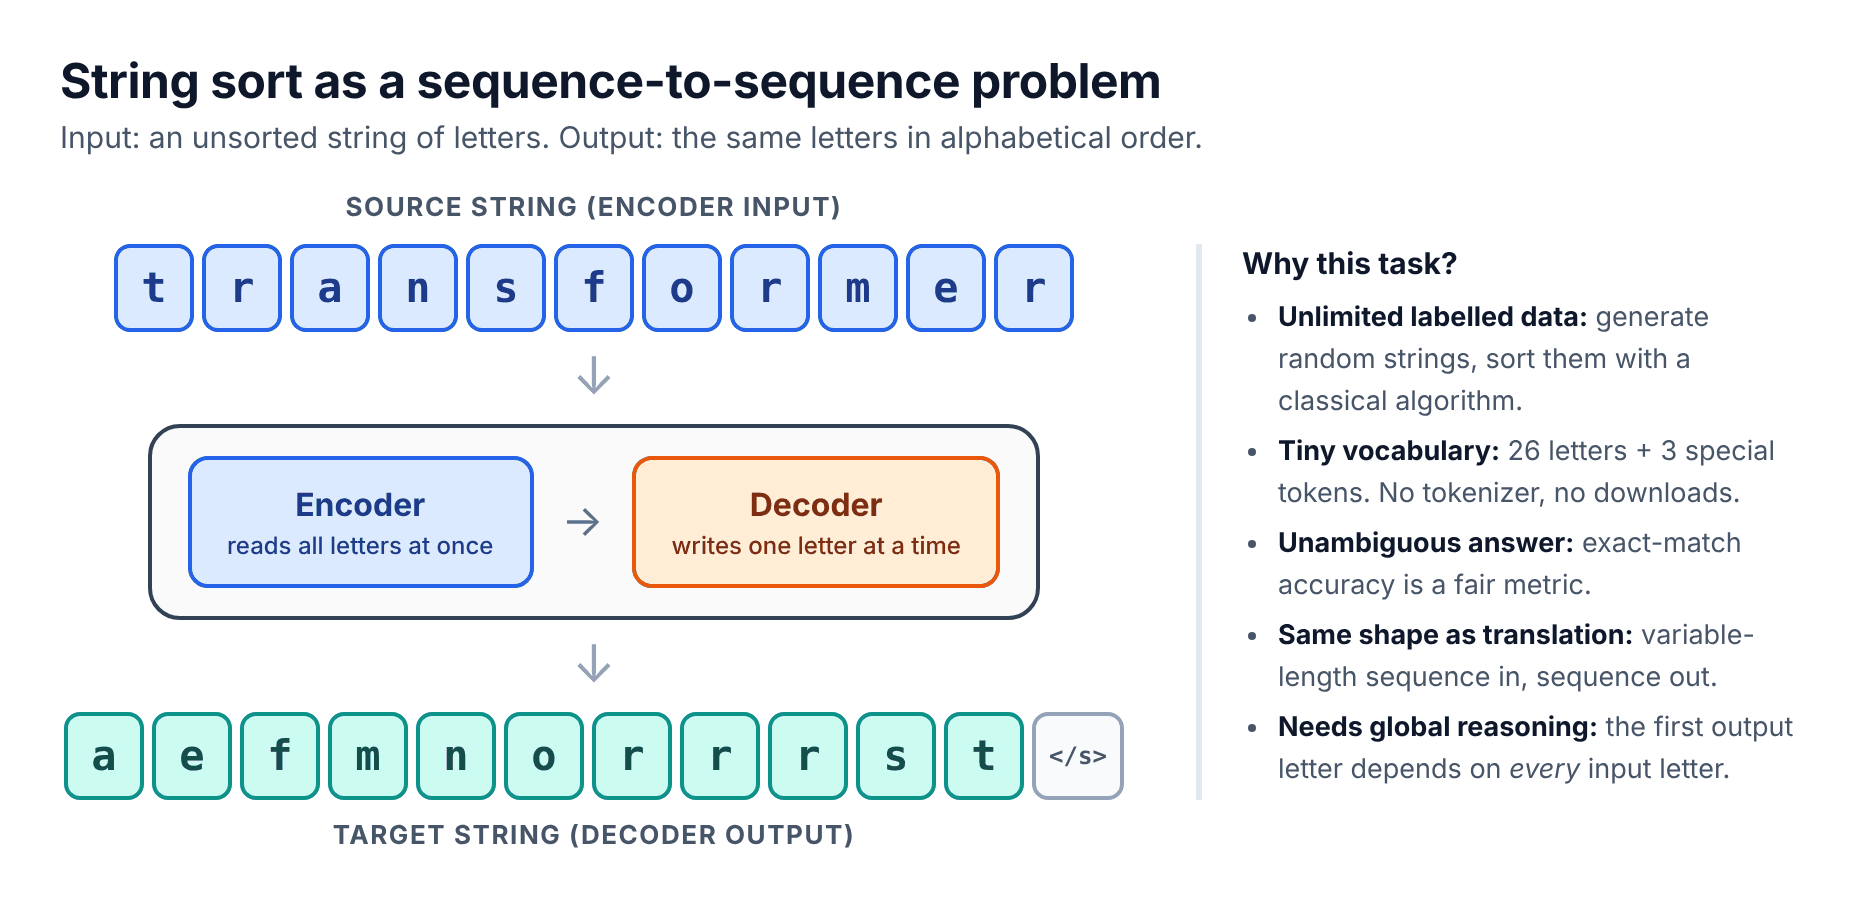</p>

### 1.1 The classical algorithm: key-indexed counting

The algs4 chapter on string sorts starts with **key-indexed counting**: when keys are small integers (here, letters with alphabet size $R=26$), we can sort in $O(N+R)$ time with no comparisons at all.
LSD and MSD radix sort apply this same procedure once per character position to sort whole *lists* of strings.

We use the algorithm in two ways:
* as the **label generator** for our synthetic dataset, and
* as a **mental model** of what the network has to learn: *which letters occur, how often, and in what order to emit them*.

<p align="center">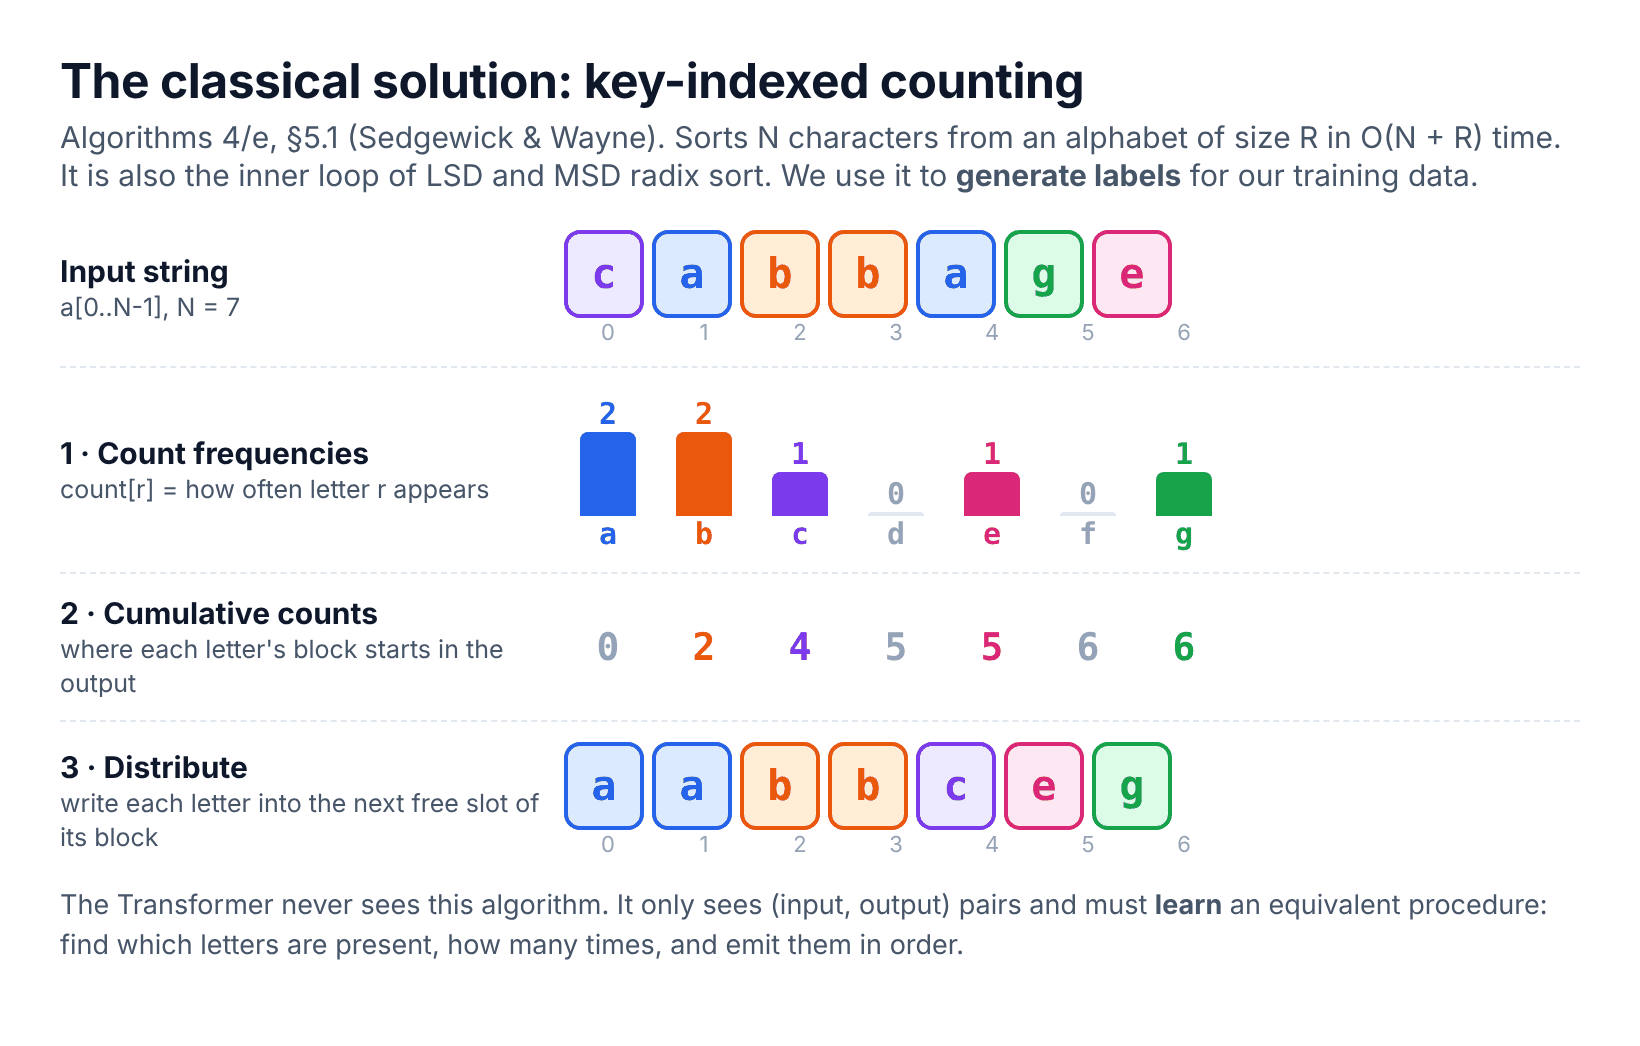</p>

In [3]:
ALPHABET = "abcdefghijklmnopqrstuvwxyz"   # R = 26 "keys"

def key_indexed_counting(s: str, alphabet: str = ALPHABET) -> str:
    # Sort the characters of s, following algs4 §5.1 (a Python port of the Java code).
    R = len(alphabet)
    index = {ch: r for r, ch in enumerate(alphabet)}

    count = [0] * (R + 1)
    for ch in s:                       # 1. count frequencies (offset by 1)
        count[index[ch] + 1] += 1
    for r in range(R):                 # 2. cumulative counts -> start index of each letter
        count[r + 1] += count[r]
    aux = [None] * len(s)
    for ch in s:                       # 3. distribute each letter into its block
        aux[count[index[ch]]] = ch
        count[index[ch]] += 1
    return "".join(aux)                # 4. copy back

for word in ["cabbage", "transformer", "princeton"]:
    print(f"{word:>12s}  ->  {key_indexed_counting(word)}")

# Sanity check against Python's built-in sort
assert all(key_indexed_counting(w) == "".join(sorted(w)) for w in ["cabbage", "zyx", "aaa", "q"])

     cabbage  ->  aabbceg
 transformer  ->  aefmnorrrst
   princeton  ->  ceinnoprt


### 1.2 Vocabulary: letters and special tokens

The model works with integer **token ids**. Besides the 26 letters we need three special tokens, the same ones the Annotated Transformer uses:

| token | id | role |
|---|---|---|
| `<pad>` | 0 | fills short sequences up to the batch length (the Annotated Transformer calls it `<blank>`) |
| `<s>` | 1 | start-of-sequence: the first input to the decoder |
| `</s>` | 2 | end-of-sequence: the decoder emits it to say "I'm done" |

In [4]:
SPECIALS = ["<pad>", "<s>", "</s>"]
ITOS = SPECIALS + list(ALPHABET)               # id -> token
STOI = {tok: i for i, tok in enumerate(ITOS)}  # token -> id
PAD, BOS, EOS = STOI["<pad>"], STOI["<s>"], STOI["</s>"]
VOCAB_SIZE = len(ITOS)

def encode(s: str, stoi=STOI) -> list:
    return [stoi[ch] for ch in s]

def decode_ids(ids, itos=ITOS) -> str:
    # Token ids -> string. Stops at </s> and skips <pad>/<s>.
    out = []
    for i in ids:
        i = int(i)
        if i == EOS:
            break
        if i in (PAD, BOS):
            continue
        out.append(itos[i])
    return "".join(out)

print("vocabulary size:", VOCAB_SIZE)
print("encode('cab')  =", encode("cab"))
print("decode_ids([1, 5, 3, 4, 2, 0]) =", repr(decode_ids([1, 5, 3, 4, 2, 0])))

vocabulary size: 29
encode('cab')  = [5, 3, 4]
decode_ids([1, 5, 3, 4, 2, 0]) = 'cab'


### 1.3 Synthesize the dataset

* Strings of random length **3–12** with letters drawn uniformly from the alphabet.
* Labels come from `key_indexed_counting`.
* Separate **train / validation / test** sets, each generated with its own seed.

In [5]:
MIN_LEN, MAX_LEN = 3, 12

def random_string(rng: random.Random, min_len: int = MIN_LEN, max_len: int = MAX_LEN) -> str:
    length = rng.randint(min_len, max_len)
    return "".join(rng.choice(ALPHABET) for _ in range(length))

def make_dataset(n: int, seed: int, min_len: int = MIN_LEN, max_len: int = MAX_LEN) -> list:
    # Returns n (source, target) pairs such as ('cabbage', 'aabbceg').
    rng = random.Random(seed)
    data = []
    for _ in range(n):
        s = random_string(rng, min_len, max_len)
        data.append((s, key_indexed_counting(s)))
    return data

train_data = make_dataset(50_000, seed=1)
val_data   = make_dataset(1_000,  seed=2)
test_data  = make_dataset(2_000,  seed=3)

print(f"train={len(train_data):,}  val={len(val_data):,}  test={len(test_data):,}")
train_set = {s for s, _ in train_data}
print("test strings that also appear in train:", sum(s in train_set for s, _ in test_data))
print()
for src, tgt in train_data[:5]:
    print(f"  {src:<12s} -> {tgt}")

train=50,000  val=1,000  test=2,000
test strings that also appear in train: 56

  szyci        -> cisyz
  pyop         -> oppy
  zgdpamnty    -> adgmnptyz
  woi          -> iow
  sdkaaa       -> aaadks


### 1.4 From strings to a mini-batch

Strings have different lengths, so we **pad** them into a rectangular tensor. The decoder is trained with **teacher forcing**:
its input is the target shifted right by one position (it starts with `<s>`), and it must predict the next token at every position.

<p align="center">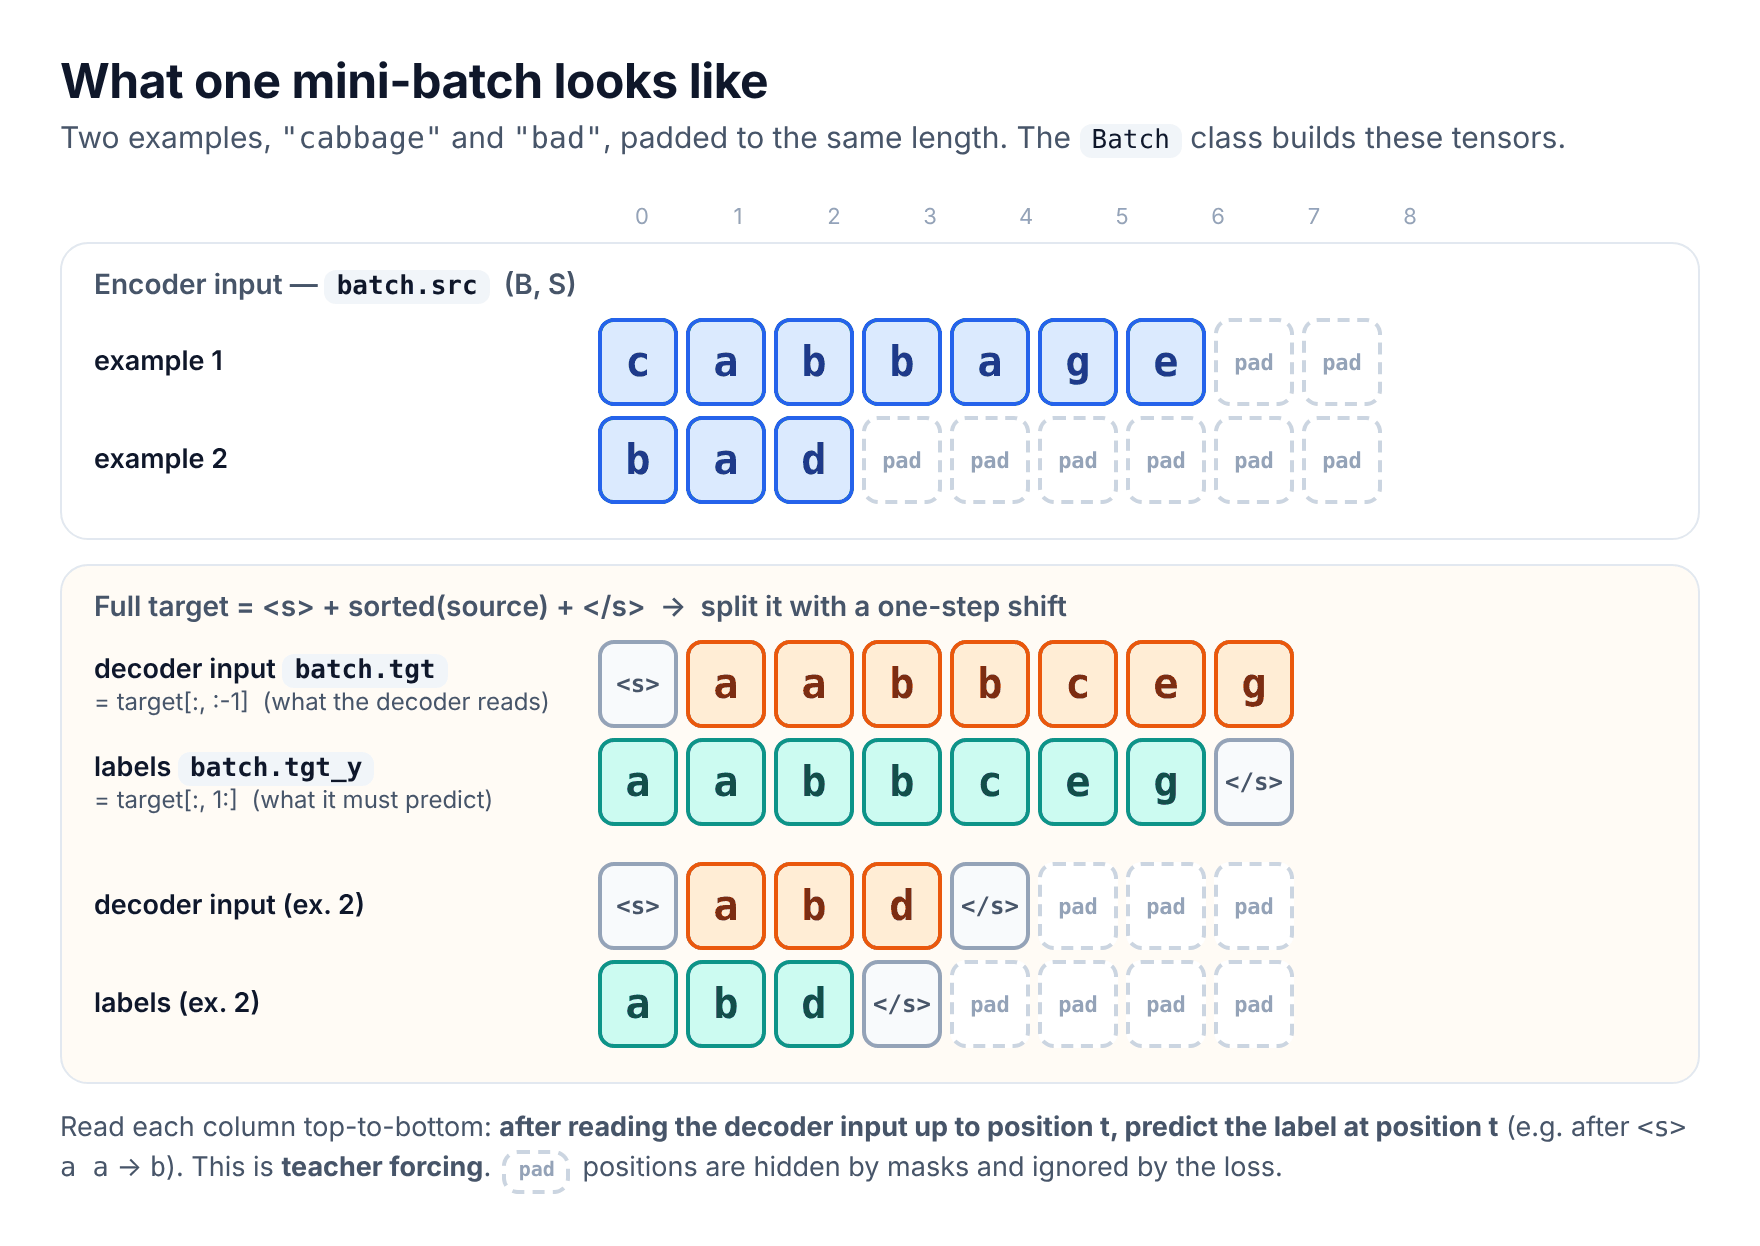</p>

📎 The `Batch` class below is the one from the Annotated Transformer (section *Batches and Masking*), with comments added.
Masks are boolean: **`True` = this position may be attended to.**

In [6]:
def to_tensor(strings, add_bos=False, add_eos=False, stoi=STOI) -> torch.Tensor:
    # Encode a list of strings and right-pad them into a (batch, max_len) LongTensor.
    seqs = [([BOS] if add_bos else []) + encode(s, stoi) + ([EOS] if add_eos else []) for s in strings]
    max_len = max(len(x) for x in seqs)
    return torch.tensor([x + [PAD] * (max_len - len(x)) for x in seqs], dtype=torch.long)


def subsequent_mask(size: int) -> torch.Tensor:
    # Causal mask: position i may only look at positions <= i.  Shape (1, size, size).
    return torch.tril(torch.ones(1, size, size, dtype=torch.bool))


class Batch:
    # Holds a batch of source/target sentences and their masks (as in the Annotated Transformer).
    def __init__(self, src, tgt=None, pad=PAD):
        self.src = src                                    # (B, S)
        self.src_mask = (src != pad).unsqueeze(-2)        # (B, 1, S): hide <pad> keys
        if tgt is not None:
            self.tgt = tgt[:, :-1]                        # (B, T) decoder input:  <s> y1 ... y_n
            self.tgt_y = tgt[:, 1:]                       # (B, T) labels:         y1 ... y_n </s>
            self.tgt_mask = self.make_std_mask(self.tgt, pad)   # (B, T, T)
            self.ntokens = (self.tgt_y != pad).sum()      # number of real (non-pad) labels

    @staticmethod
    def make_std_mask(tgt, pad):
        # Hide padding AND future words.
        tgt_mask = (tgt != pad).unsqueeze(-2)                       # (B, 1, T)
        return tgt_mask & subsequent_mask(tgt.size(-1)).to(tgt.device)  # (B, T, T)


def make_batch(pairs, stoi=STOI) -> Batch:
    src = to_tensor([s for s, _ in pairs], stoi=stoi).to(device)
    tgt = to_tensor([t for _, t in pairs], add_bos=True, add_eos=True, stoi=stoi).to(device)
    return Batch(src, tgt)


demo = make_batch([("cabbage", "aabbceg"), ("bad", "abd")])
print("src   :", demo.src.shape);   print(demo.src.cpu())
print("tgt   :", demo.tgt.shape);   print(demo.tgt.cpu())
print("tgt_y :", demo.tgt_y.shape); print(demo.tgt_y.cpu())

src   : torch.Size([2, 7])
tensor([[5, 3, 4, 4, 3, 9, 7],
        [4, 3, 6, 0, 0, 0, 0]])
tgt   : torch.Size([2, 8])
tensor([[1, 3, 3, 4, 4, 5, 7, 9],
        [1, 3, 4, 6, 2, 0, 0, 0]])
tgt_y : torch.Size([2, 8])
tensor([[3, 3, 4, 4, 5, 7, 9, 2],
        [3, 4, 6, 2, 0, 0, 0, 0]])


**What the masks look like.** Example 2 (`"bad"`) is padded. Its encoder mask hides the pads; its decoder mask hides pads *and* the future.

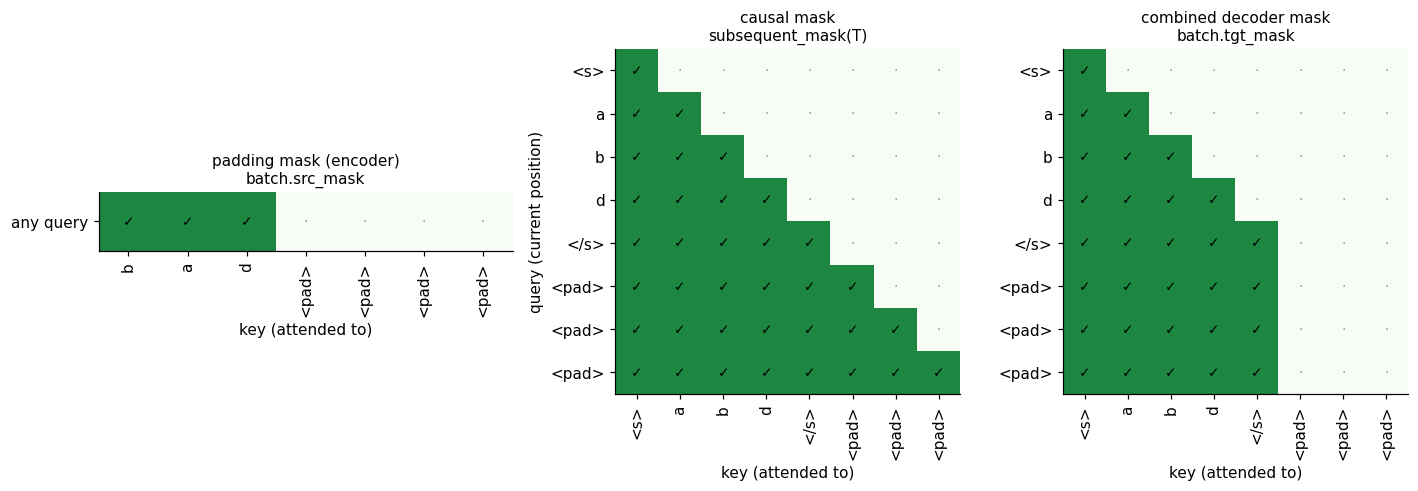

In [7]:
def show_masks(batch: Batch, i: int = 1):
    src_tokens = [ITOS[t] for t in batch.src[i].tolist()]
    tgt_tokens = [ITOS[t] for t in batch.tgt[i].tolist()]
    T = batch.tgt.size(1)
    panels = [
        ("padding mask (encoder)\nbatch.src_mask", batch.src_mask[i].cpu().float(), src_tokens, ["any query"]),
        ("causal mask\nsubsequent_mask(T)", subsequent_mask(T)[0].float(), tgt_tokens, tgt_tokens),
        ("combined decoder mask\nbatch.tgt_mask", batch.tgt_mask[i].cpu().float(), tgt_tokens, tgt_tokens),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.2, 1, 1]})
    for ax, (title, m, xt, yt) in zip(axes, panels):
        ax.imshow(m, cmap="Greens", vmin=0, vmax=1.3)
        ax.set_xticks(range(len(xt)), xt, rotation=90); ax.set_yticks(range(len(yt)), yt)
        ax.set_title(title, fontsize=10); ax.set_xlabel("key (attended to)")
        for (r, c), v in np.ndenumerate(m.numpy()):
            ax.text(c, r, "✓" if v else "·", ha="center", va="center", fontsize=9, color="black" if v else "#999")
    axes[1].set_ylabel("query (current position)")
    plt.tight_layout(); plt.show()

show_masks(demo, i=1)

🧠 **Concept check.** In the right-hand panel, why can the row for `b` see `<s>` and `a` but not `d`?
What would go wrong during training if it *could* see `d`?

---
# 2. Scaled dot-product attention &nbs

$$
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V
$$

* **Query** $q$: *what am I looking for?*
* **Key** $k$: *what do I contain, for matching?*
* **Value** $v$: *what do I pass on if I'm selected?*

Dividing by $\sqrt{d_k}$ keeps the dot products from growing with the dimension; otherwise the softmax saturates and gradients vanish.

<p align="center">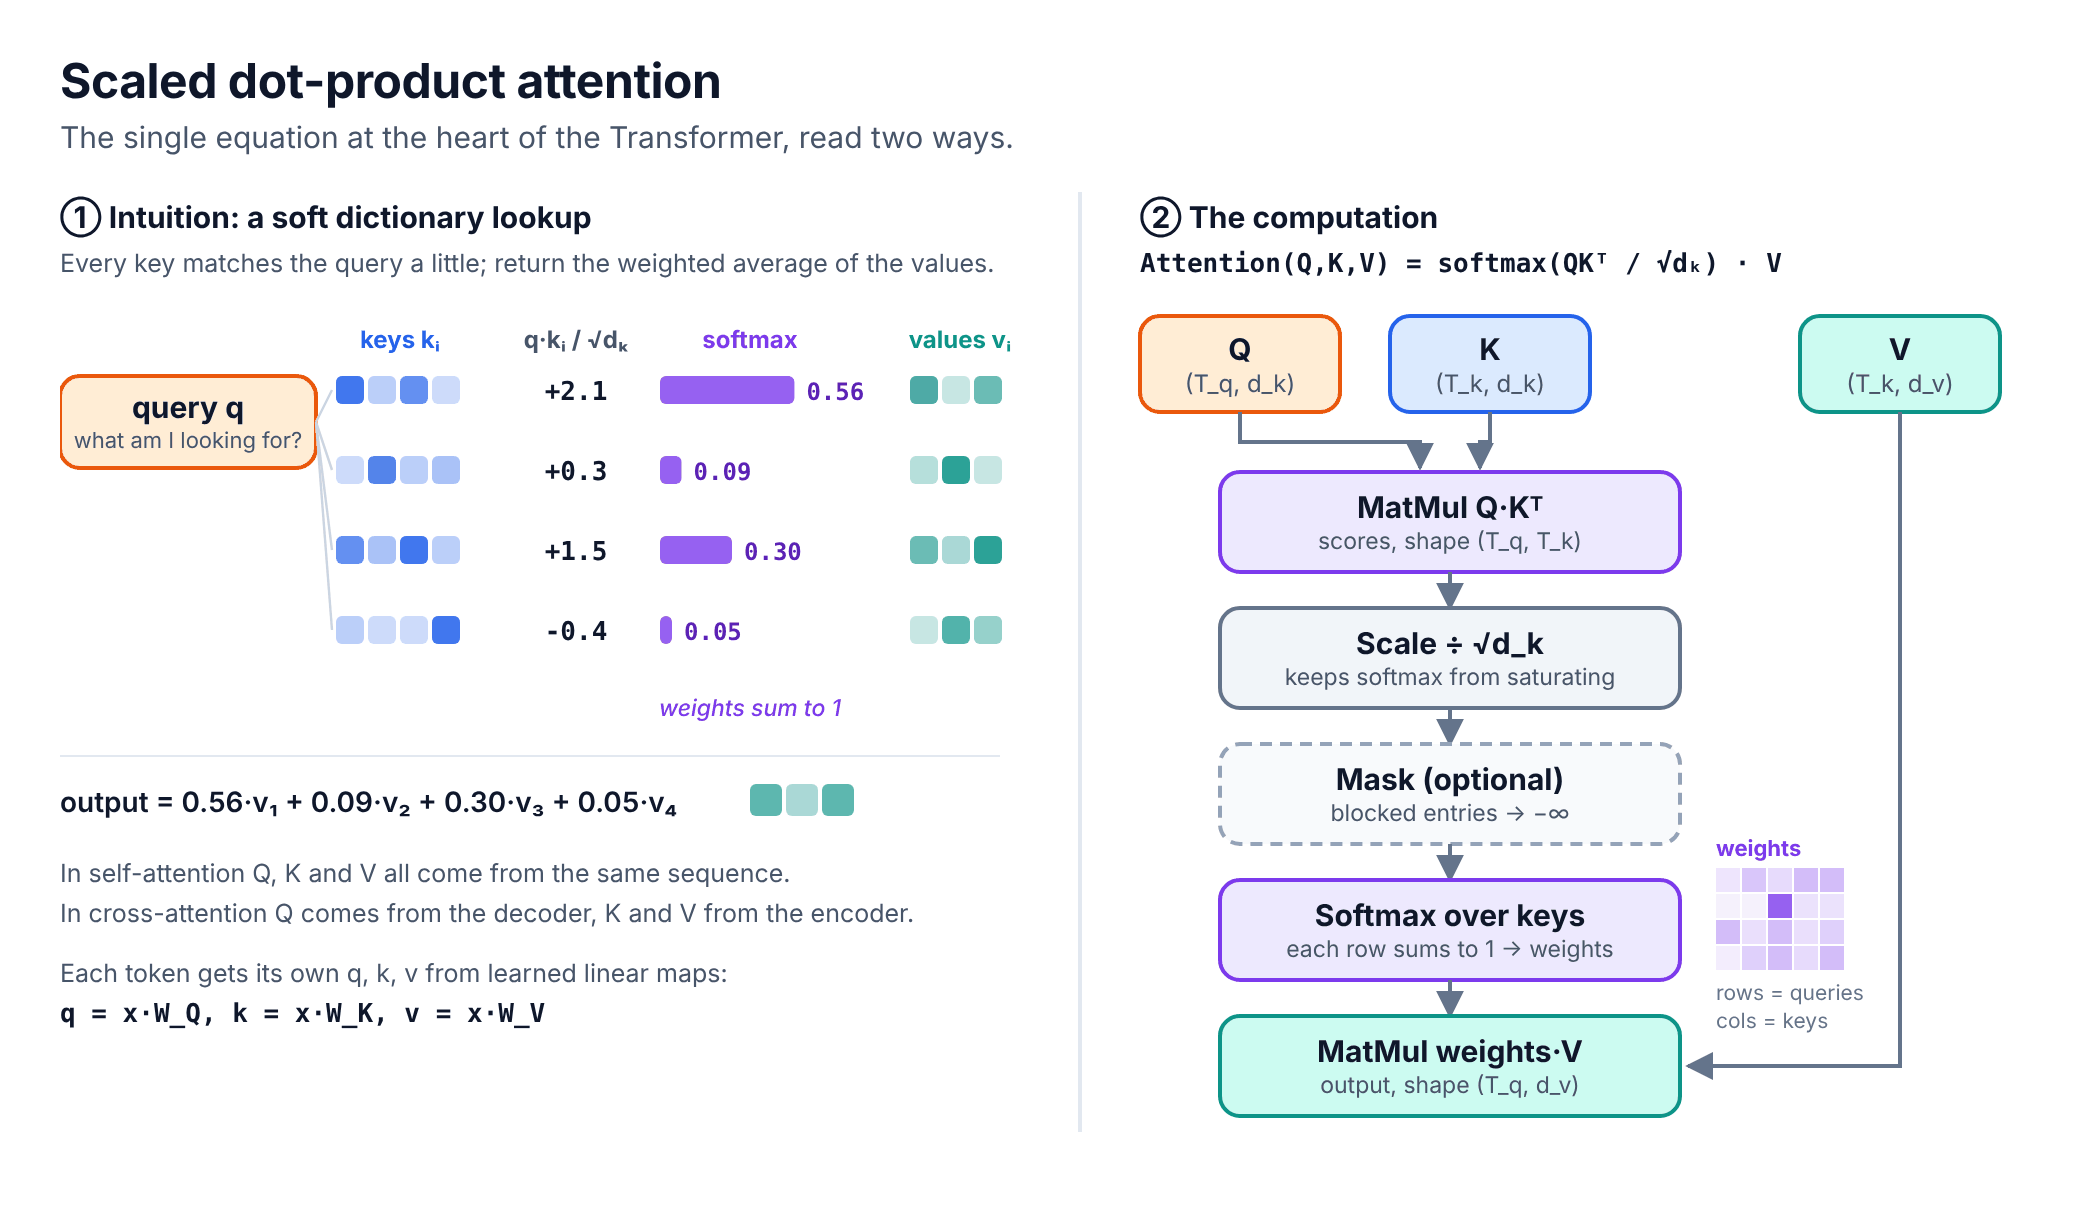</p>

### 2.1 A tiny example by hand
One query, three keys. The query points in the same direction as key 0 and key 2, so those get most of the weight.

In [8]:
q = torch.tensor([[1.0, 0.0]])            # (1 query,  d_k=2)
K = torch.tensor([[1.0, 0.0],             # (3 keys,   d_k=2)
                  [0.0, 1.0],
                  [1.0, 1.0]])
V = torch.tensor([[10.0,  0.0],           # (3 values, d_v=2)
                  [ 0.0, 10.0],
                  [ 5.0,  5.0]])

scores  = q @ K.T / math.sqrt(q.size(-1)) # (1, 3) similarity of the query to each key
weights = scores.softmax(dim=-1)          # (1, 3) non-negative and sums to 1
output  = weights @ V                     # (1, 2) weighted average of the values

print("scores :", scores.numpy().round(3))
print("weights:", weights.numpy().round(3), " sum =", weights.sum().item())
print("output :", output.numpy().round(3))

scores : [[0.707 0.    0.707]]
weights: [[0.401 0.198 0.401]]  sum = 1.0
output : [[6.017 3.983]]


### 2.2 ✍️ Your turn (3 min): implement attention
Fill in the four `TODO` lines, then run the test cell. Shapes work for any number of leading batch/head dimensions.
<details><summary><b>Hint</b></summary>

`key.transpose(-2, -1)` swaps the last two dimensions; `scores.masked_fill(mask == 0, -1e9)` blocks masked positions; `softmax(dim=-1)` normalises over keys.
</details>

In [9]:
def my_attention(query, key, value, mask=None):
    # query: (..., T_q, d_k)   key: (..., T_k, d_k)   value: (..., T_k, d_v)
    d_k = query.size(-1)
    scores = None   # TODO 1: scaled dot products, shape (..., T_q, T_k)
    if mask is not None:
        scores = None   # TODO 2: put -1e9 wherever mask == 0
    p_attn = None   # TODO 3: softmax over the keys
    output = None   # TODO 4: weighted sum of the values, shape (..., T_q, d_v)
    return output, p_attn

📎 **Reference implementation**, identical to the `attention` function in the Annotated Transformer:

In [10]:
def attention(query, key, value, mask=None, dropout=None):
    # Compute 'Scaled Dot Product Attention'.
    d_k = query.size(-1)
    scores = query @ key.transpose(-2, -1) / math.sqrt(d_k)   # (..., T_q, T_k)
    if mask is not None:
        scores = scores.masked_fill(mask == 0, -1e9)            # blocked -> ~0 after softmax
    p_attn = scores.softmax(dim=-1)                             # each row sums to 1
    if dropout is not None:
        p_attn = dropout(p_attn)
    return p_attn @ value, p_attn                               # (..., T_q, d_v), (..., T_q, T_k)


def check_attention(fn):
    torch.manual_seed(0)
    Q, K, V = torch.randn(2, 5, 8), torch.randn(2, 7, 8), torch.randn(2, 7, 4)
    mask = torch.ones(2, 1, 7, dtype=torch.bool); mask[:, :, 5:] = False   # hide last 2 keys
    try:
        out, p = fn(Q, K, V, mask)
        ref_out, ref_p = attention(Q, K, V, mask)
        assert out is not None and out.shape == (2, 5, 4), f"wrong output shape: {getattr(out, 'shape', None)}"
        assert torch.allclose(p.sum(-1), torch.ones(2, 5), atol=1e-5), "rows of p_attn must sum to 1"
        assert p[..., 5:].abs().max() < 1e-6, "masked keys must get zero weight"
        assert torch.allclose(out, ref_out, atol=1e-5), "values differ from the reference"
        print("✅ all attention tests passed")
    except Exception as e:
        print("❌", type(e).__name__, e)

check_attention(my_attention)   # fails until you fill in the TODOs
check_attention(attention)      # the reference implementation passes

❌ AssertionError wrong output shape: None
✅ all attention tests passed


---
# 3. Multi-head attention &nbsp

One attention head computes **one** weighted average per position, so it can only focus on one kind of relationship at a time.
Multi-head attention runs $h$ smaller heads in parallel, each on its own learned projection:

$$
\text{head}_i = \operatorname{Attention}(QW_i^Q,\;KW_i^K,\;VW_i^V), \qquad
\operatorname{MultiHead}(Q,K,V) = \operatorname{Concat}(\text{head}_1,\dots,\text{head}_h)\,W^O
$$

We use $d_{\text{model}}=64$ and $h=4$, so each head works in $d_k = 64/4 = 16$ dimensions.

<p align="center">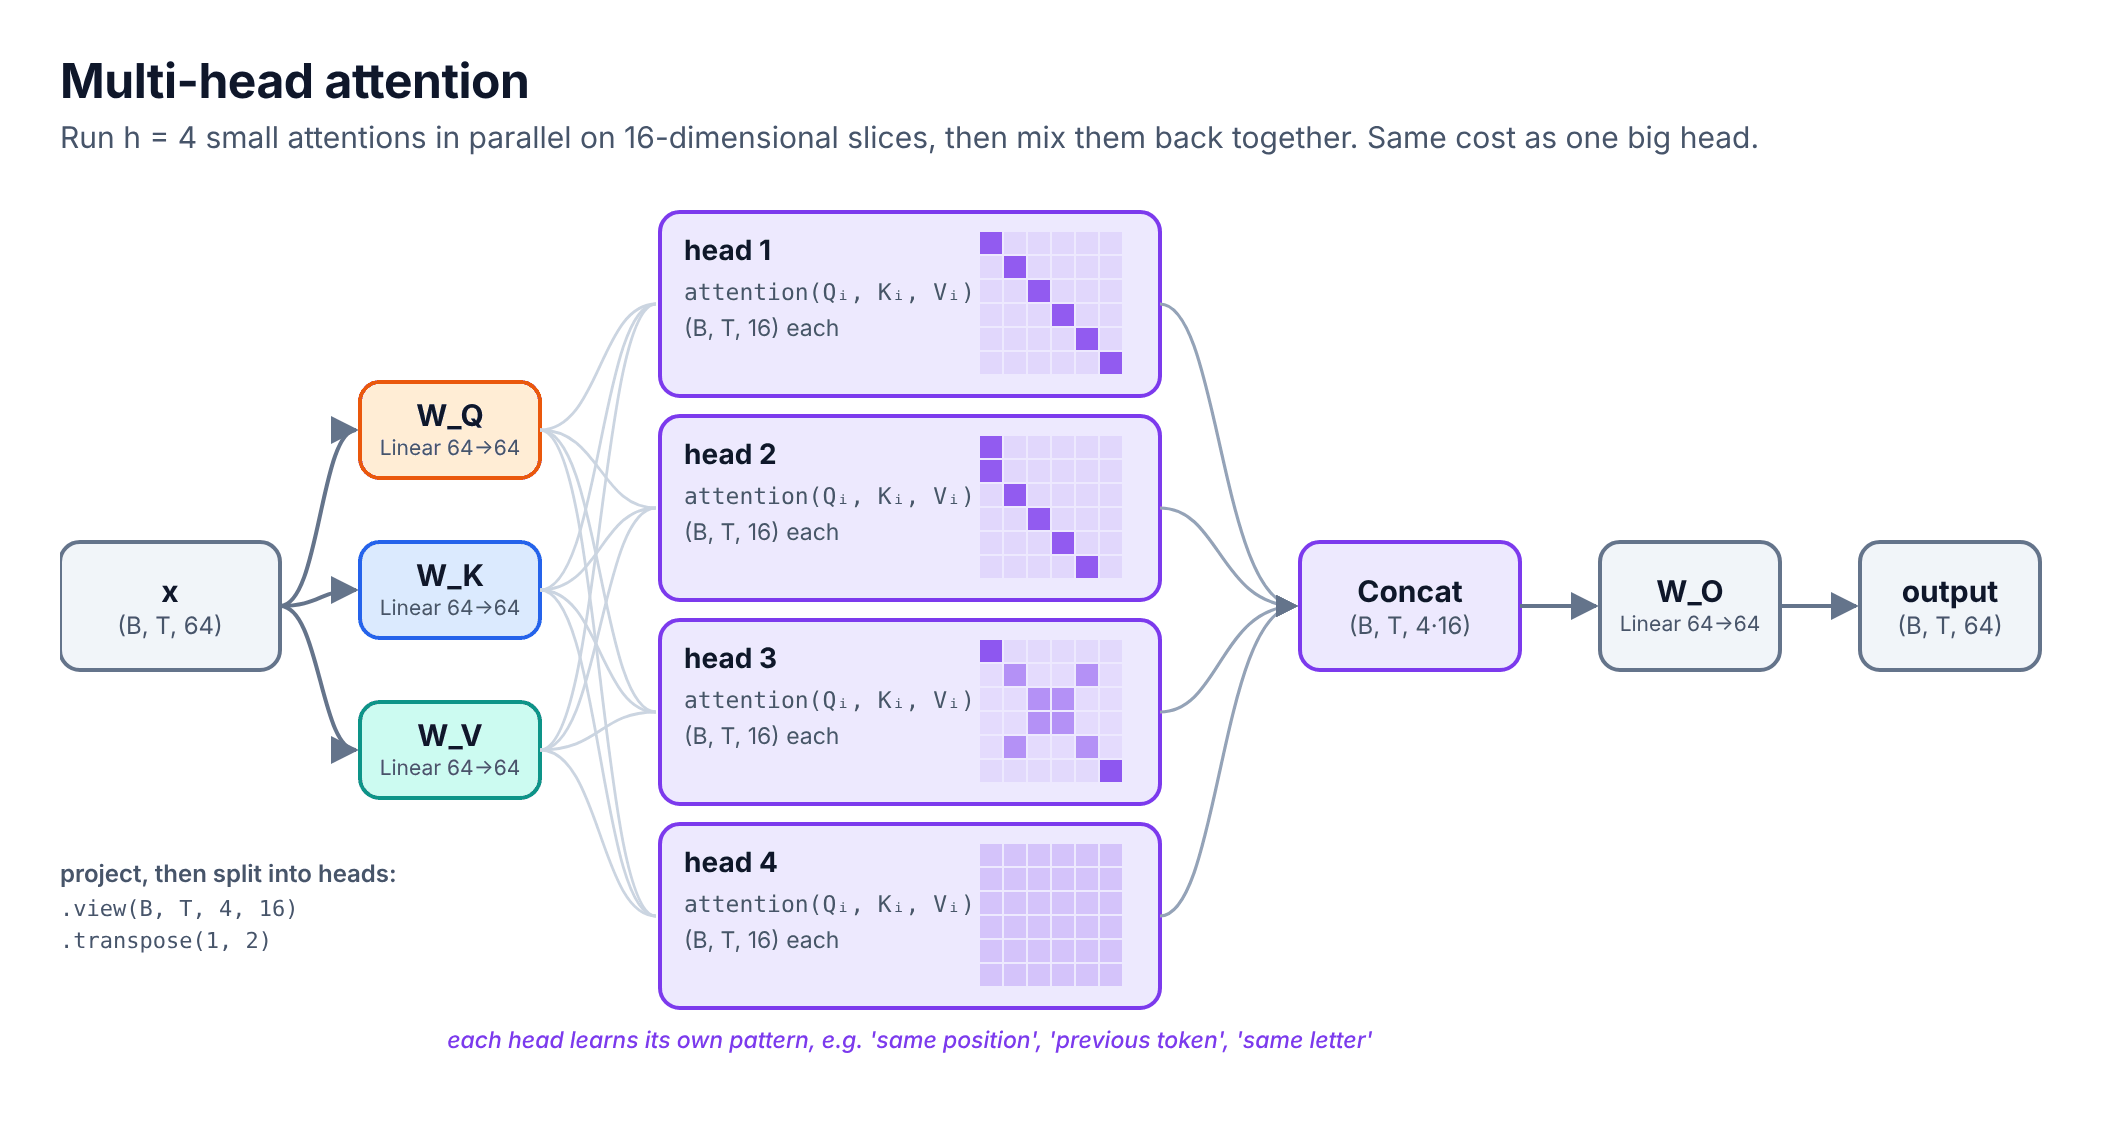</p>

📎 Same computation as `MultiHeadedAttention` in the Annotated Transformer. We name the four projections `w_q, w_k, w_v, w_o` instead of using `clones(nn.Linear, 4)` so each line maps to the figure.

In [11]:
class MultiHeadedAttention(nn.Module):
    def __init__(self, h: int, d_model: int, dropout: float = 0.1):
        super().__init__()
        assert d_model % h == 0, "d_model must be divisible by the number of heads"
        self.h, self.d_k = h, d_model // h
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.attn = None                          # last attention weights, kept for visualisation

    def forward(self, query, key, value, mask=None):
        # query: (B, T_q, d_model); key/value: (B, T_k, d_model); mask: (B, 1 or T_q, T_k)
        B = query.size(0)
        if mask is not None:
            mask = mask.unsqueeze(1)              # same mask for every head -> (B, 1, *, T_k)

        def split_heads(x):                       # (B, T, d_model) -> (B, h, T, d_k)
            return x.view(B, -1, self.h, self.d_k).transpose(1, 2)

        Q = split_heads(self.w_q(query))
        K = split_heads(self.w_k(key))
        V = split_heads(self.w_v(value))

        x, self.attn = attention(Q, K, V, mask=mask, dropout=self.dropout)   # x: (B, h, T_q, d_k)

        x = x.transpose(1, 2).contiguous().view(B, -1, self.h * self.d_k)    # concat -> (B, T_q, d_model)
        return self.w_o(x)


mha = MultiHeadedAttention(h=4, d_model=64)
x = torch.randn(2, 7, 64)
out = mha(x, x, x)
print("input :", tuple(x.shape), "\noutput:", tuple(out.shape), "\nattn  :", tuple(mha.attn.shape), " (B, heads, T_q, T_k)")
assert out.shape == x.shape

input : (2, 7, 64) 
output: (2, 7, 64) 
attn  : (2, 4, 7, 7)  (B, heads, T_q, T_k)


---
# 4. Embeddings and positional encoding &nbsp

Attention compares tokens by content only. Without extra information, `"cab"` and `"bac"` look identical to it.
The Transformer therefore **adds** a position-dependent vector to each token embedding:

$$
PE_{(pos,\,2i)}=\sin\!\left(\frac{pos}{10000^{2i/d_{\text{model}}}}\right),\qquad
PE_{(pos,\,2i+1)}=\cos\!\left(\frac{pos}{10000^{2i/d_{\text{model}}}}\right)
$$

<p align="center">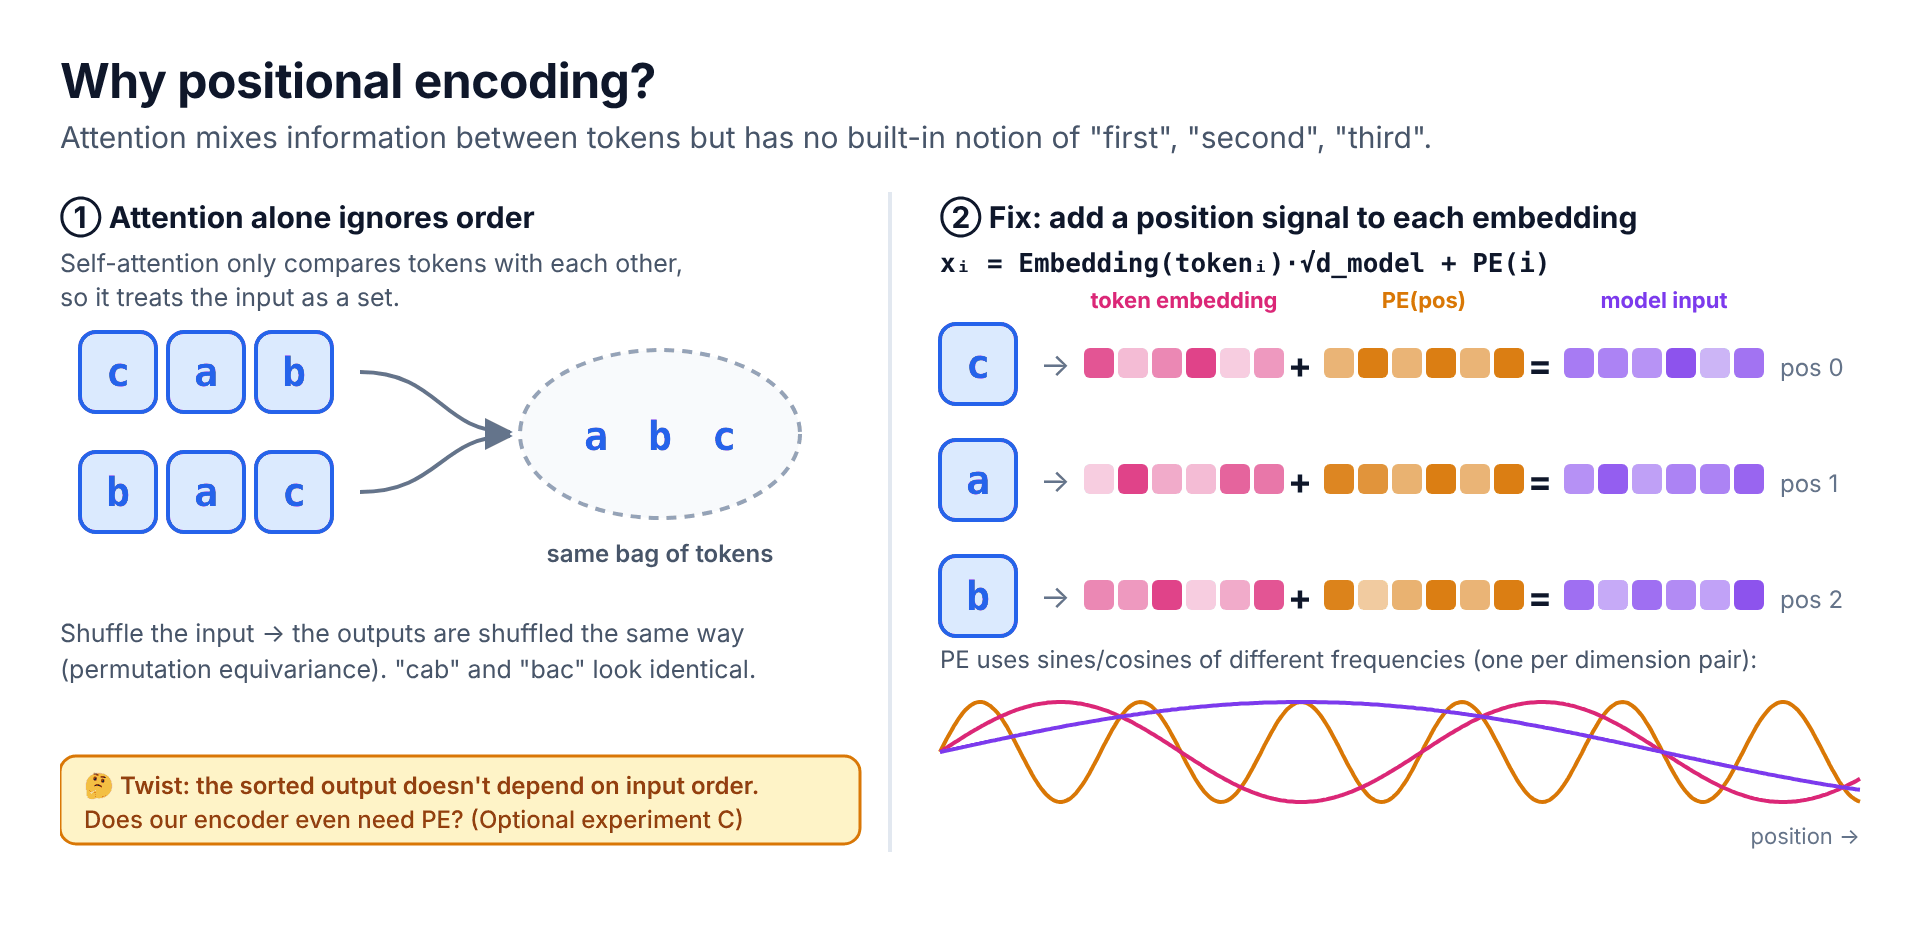</p>

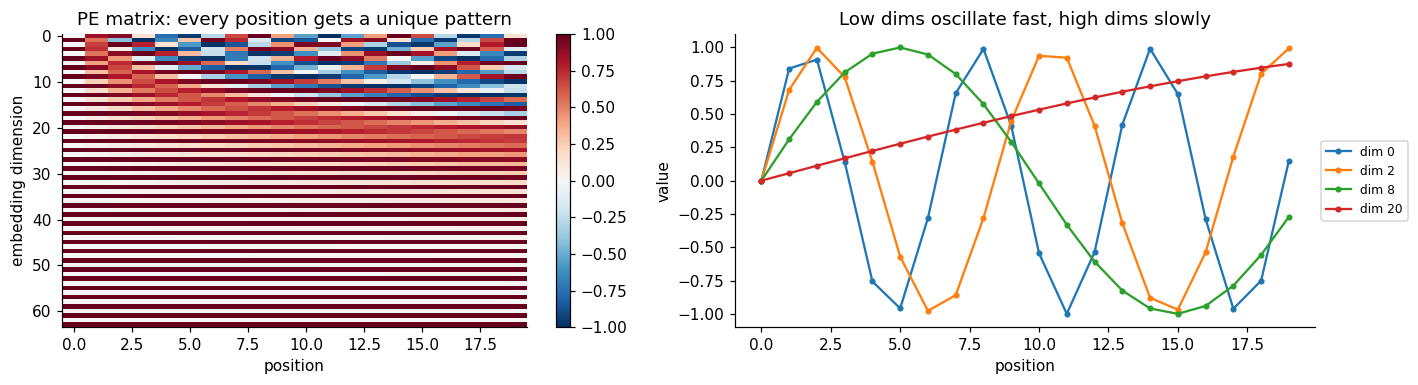

In [12]:
class Embeddings(nn.Module):
    # Token id -> vector, scaled by sqrt(d_model) as in the paper.
    def __init__(self, d_model: int, vocab: int):
        super().__init__()
        self.lut = nn.Embedding(vocab, d_model)
        self.d_model = d_model

    def forward(self, x):                                  # (B, T) -> (B, T, d_model)
        return self.lut(x) * math.sqrt(self.d_model)


class PositionalEncoding(nn.Module):
    # Adds the fixed sinusoidal position signal. Set enabled=False for the ablation in Optional C.
    def __init__(self, d_model: int, dropout: float, max_len: int = 64, enabled: bool = True):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)
        self.enabled = enabled
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(max_len).unsqueeze(1)                           # (max_len, 1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * -(math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))                             # (1, max_len, d_model)

    def forward(self, x):                                  # (B, T, d_model) -> same
        if self.enabled:
            x = x + self.pe[:, : x.size(1)]
        return self.dropout(x)


pe = PositionalEncoding(d_model=64, dropout=0.0).pe[0, :20]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.6))
im = ax1.imshow(pe.T, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
ax1.set(xlabel="position", ylabel="embedding dimension", title="PE matrix: every position gets a unique pattern")
plt.colorbar(im, ax=ax1)
for d in [0, 2, 8, 20]:
    ax2.plot(pe[:, d], marker=".", label=f"dim {d}")
ax2.set(xlabel="position", ylabel="value", title="Low dims oscillate fast, high dims slowly")
ax2.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); plt.show()

---
# 5. Assembling the Transformer

Here is everything we have to build. **Each box is one small class**, and the next cells implement them bottom-up.

<p align="center">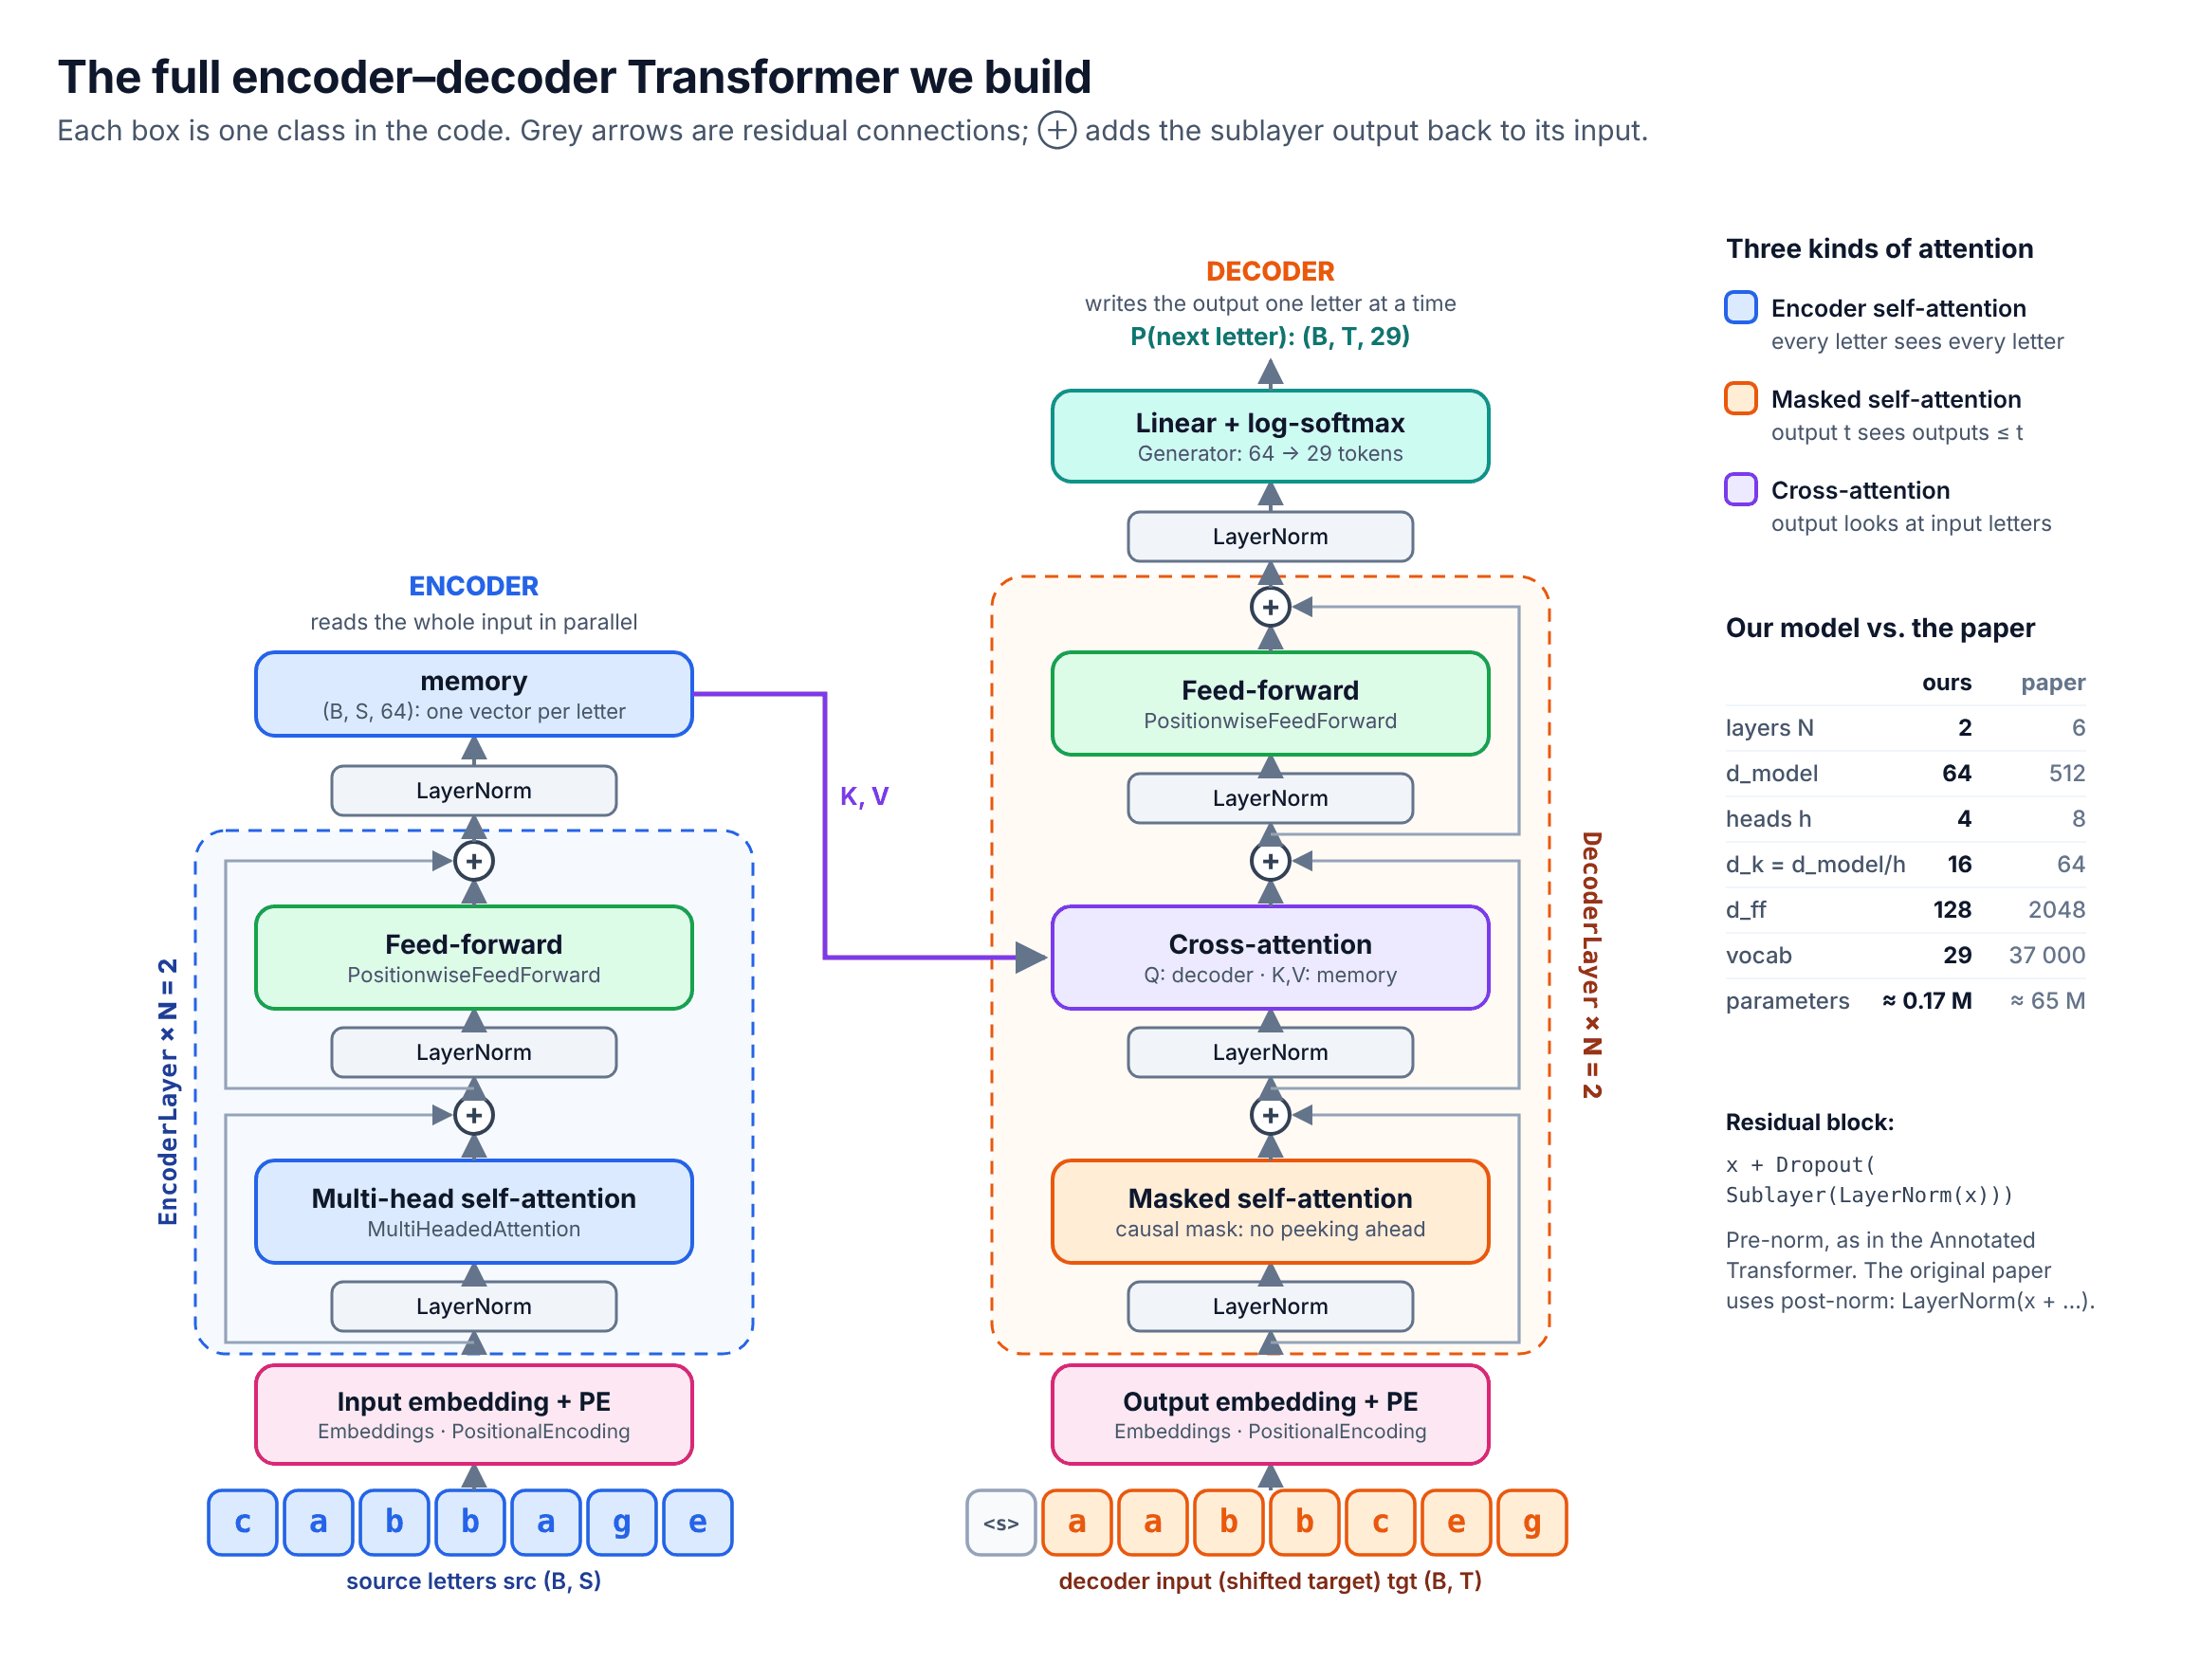</p>

### 5.1 Building blocks: feed-forward network and residual connection

* **Position-wise feed-forward:** $\text{FFN}(x)=\max(0,\,xW_1+b_1)\,W_2+b_2$, applied to every position independently. Attention *mixes* positions; the FFN *processes* each one.
* **Sublayer connection:** every sublayer is wrapped as `x + Dropout(Sublayer(LayerNorm(x)))`. The residual path lets gradients flow straight through deep stacks.

📎 The Annotated Transformer also writes its own `LayerNorm`; we use PyTorch's `nn.LayerNorm`, which does the same thing.

In [13]:
def clones(module: nn.Module, N: int) -> nn.ModuleList:
    # Produce N identical (independently trained) copies of a layer.
    return nn.ModuleList([copy.deepcopy(module) for _ in range(N)])


class PositionwiseFeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int, dropout: float = 0.1):
        super().__init__()
        self.w_1 = nn.Linear(d_model, d_ff)
        self.w_2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):                                  # (B, T, d_model) -> same
        return self.w_2(self.dropout(self.w_1(x).relu()))


class SublayerConnection(nn.Module):
    # Pre-norm residual block:  x + Dropout(Sublayer(LayerNorm(x)))
    def __init__(self, size: int, dropout: float):
        super().__init__()
        self.norm = nn.LayerNorm(size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, sublayer):
        return x + self.dropout(sublayer(self.norm(x)))

### 5.2 Encoder

An encoder layer is two sublayers: **self-attention** (every letter looks at every other letter) and the **feed-forward** network.
The `Encoder` stacks $N$ layers and applies a final LayerNorm. Its output is called the **memory**.

In [14]:
class EncoderLayer(nn.Module):
    def __init__(self, size, self_attn, feed_forward, dropout):
        super().__init__()
        self.self_attn = self_attn
        self.feed_forward = feed_forward
        self.sublayer = clones(SublayerConnection(size, dropout), 2)
        self.size = size

    def forward(self, x, mask):
        x = self.sublayer[0](x, lambda x: self.self_attn(x, x, x, mask))   # Q = K = V = x
        return self.sublayer[1](x, self.feed_forward)


class Encoder(nn.Module):
    def __init__(self, layer: EncoderLayer, N: int):
        super().__init__()
        self.layers = clones(layer, N)
        self.norm = nn.LayerNorm(layer.size)

    def forward(self, x, mask):                            # x: (B, S, d_model)
        for layer in self.layers:
            x = layer(x, mask)
        return self.norm(x)                                # memory: (B, S, d_model)

### 5.3 Decoder

A decoder layer has **three** sublayers:
1. **masked self-attention** over the letters written so far (`tgt_mask` hides the future),
2. **cross-attention**: queries come from the decoder, keys and values from the encoder **memory**, so the decoder can look at the input letters,
3. the **feed-forward** network.

In [15]:
class DecoderLayer(nn.Module):
    def __init__(self, size, self_attn, src_attn, feed_forward, dropout):
        super().__init__()
        self.size = size
        self.self_attn = self_attn          # masked self-attention
        self.src_attn = src_attn            # cross-attention ("source attention")
        self.feed_forward = feed_forward
        self.sublayer = clones(SublayerConnection(size, dropout), 3)

    def forward(self, x, memory, src_mask, tgt_mask):
        m = memory
        x = self.sublayer[0](x, lambda x: self.self_attn(x, x, x, tgt_mask))   # look at previous outputs
        x = self.sublayer[1](x, lambda x: self.src_attn(x, m, m, src_mask))    # look at the input string
        return self.sublayer[2](x, self.feed_forward)


class Decoder(nn.Module):
    def __init__(self, layer: DecoderLayer, N: int):
        super().__init__()
        self.layers = clones(layer, N)
        self.norm = nn.LayerNorm(layer.size)

    def forward(self, x, memory, src_mask, tgt_mask):      # x: (B, T, d_model)
        for layer in self.layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return self.norm(x)                                # (B, T, d_model)

### 5.4 Putting it together: `EncoderDecoder` and `make_model`
`make_model` is the same function as in the Annotated Transformer. Only the default sizes are smaller so the model trains live.

In [16]:
class Generator(nn.Module):
    # Final Linear + log-softmax: d_model -> log-probabilities over the vocabulary.
    def __init__(self, d_model: int, vocab: int):
        super().__init__()
        self.proj = nn.Linear(d_model, vocab)

    def forward(self, x):
        return F.log_softmax(self.proj(x), dim=-1)


class EncoderDecoder(nn.Module):
    def __init__(self, encoder, decoder, src_embed, tgt_embed, generator):
        super().__init__()
        self.encoder, self.decoder = encoder, decoder
        self.src_embed, self.tgt_embed = src_embed, tgt_embed
        self.generator = generator

    def encode(self, src, src_mask):
        return self.encoder(self.src_embed(src), src_mask)

    def decode(self, memory, src_mask, tgt, tgt_mask):
        return self.decoder(self.tgt_embed(tgt), memory, src_mask, tgt_mask)

    def forward(self, src, tgt, src_mask, tgt_mask):
        return self.decode(self.encode(src, src_mask), src_mask, tgt, tgt_mask)


def make_model(src_vocab, tgt_vocab, N=2, d_model=64, d_ff=128, h=4, dropout=0.1, src_positions=True):
    # Paper defaults: N=6, d_model=512, d_ff=2048, h=8.
    c = copy.deepcopy
    attn = MultiHeadedAttention(h, d_model, dropout)
    ff = PositionwiseFeedForward(d_model, d_ff, dropout)
    model = EncoderDecoder(
        Encoder(EncoderLayer(d_model, c(attn), c(ff), dropout), N),
        Decoder(DecoderLayer(d_model, c(attn), c(attn), c(ff), dropout), N),
        nn.Sequential(Embeddings(d_model, src_vocab), PositionalEncoding(d_model, dropout, enabled=src_positions)),
        nn.Sequential(Embeddings(d_model, tgt_vocab), PositionalEncoding(d_model, dropout)),
        Generator(d_model, tgt_vocab),
    )
    for p in model.parameters():          # Glorot / Xavier initialisation, as in the Annotated Transformer
        if p.dim() > 1:
            nn.init.xavier_uniform_(p)
    return model

### 5.5 Shape check (always do this before training!)

In [17]:
CONFIG = dict(N=2, d_model=64, d_ff=128, h=4, dropout=0.1)

set_seed(0)
model = make_model(VOCAB_SIZE, VOCAB_SIZE, **CONFIG).to(device)

batch = make_batch(train_data[:8])
memory = model.encode(batch.src, batch.src_mask)
hidden = model.decode(memory, batch.src_mask, batch.tgt, batch.tgt_mask)
log_probs = model.generator(hidden)

print(f"src        {tuple(batch.src.shape)}   (B, S)")
print(f"memory     {tuple(memory.shape)}  (B, S, d_model)")
print(f"tgt        {tuple(batch.tgt.shape)}   (B, T)")
print(f"hidden     {tuple(hidden.shape)}  (B, T, d_model)")
print(f"log_probs  {tuple(log_probs.shape)}  (B, T, vocab)")
assert log_probs.shape == (*batch.tgt.shape, VOCAB_SIZE)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\ntrainable parameters: {n_params:,}  (the base model in the paper has ~65 million)")

src        (8, 11)   (B, S)
memory     (8, 11, 64)  (B, S, d_model)
tgt        (8, 12)   (B, T)
hidden     (8, 12, 64)  (B, T, d_model)
log_probs  (8, 12, 29)  (B, T, vocab)

trainable parameters: 173,277  (the base model in the paper has ~65 million)


🧠 **Concept check.** Which of the three attention modules in the model use `src_mask`, and which use `tgt_mask`? *(Look at `EncoderLayer.forward` and `DecoderLayer.forward`.)*

---
# 6. Training

<p align="center">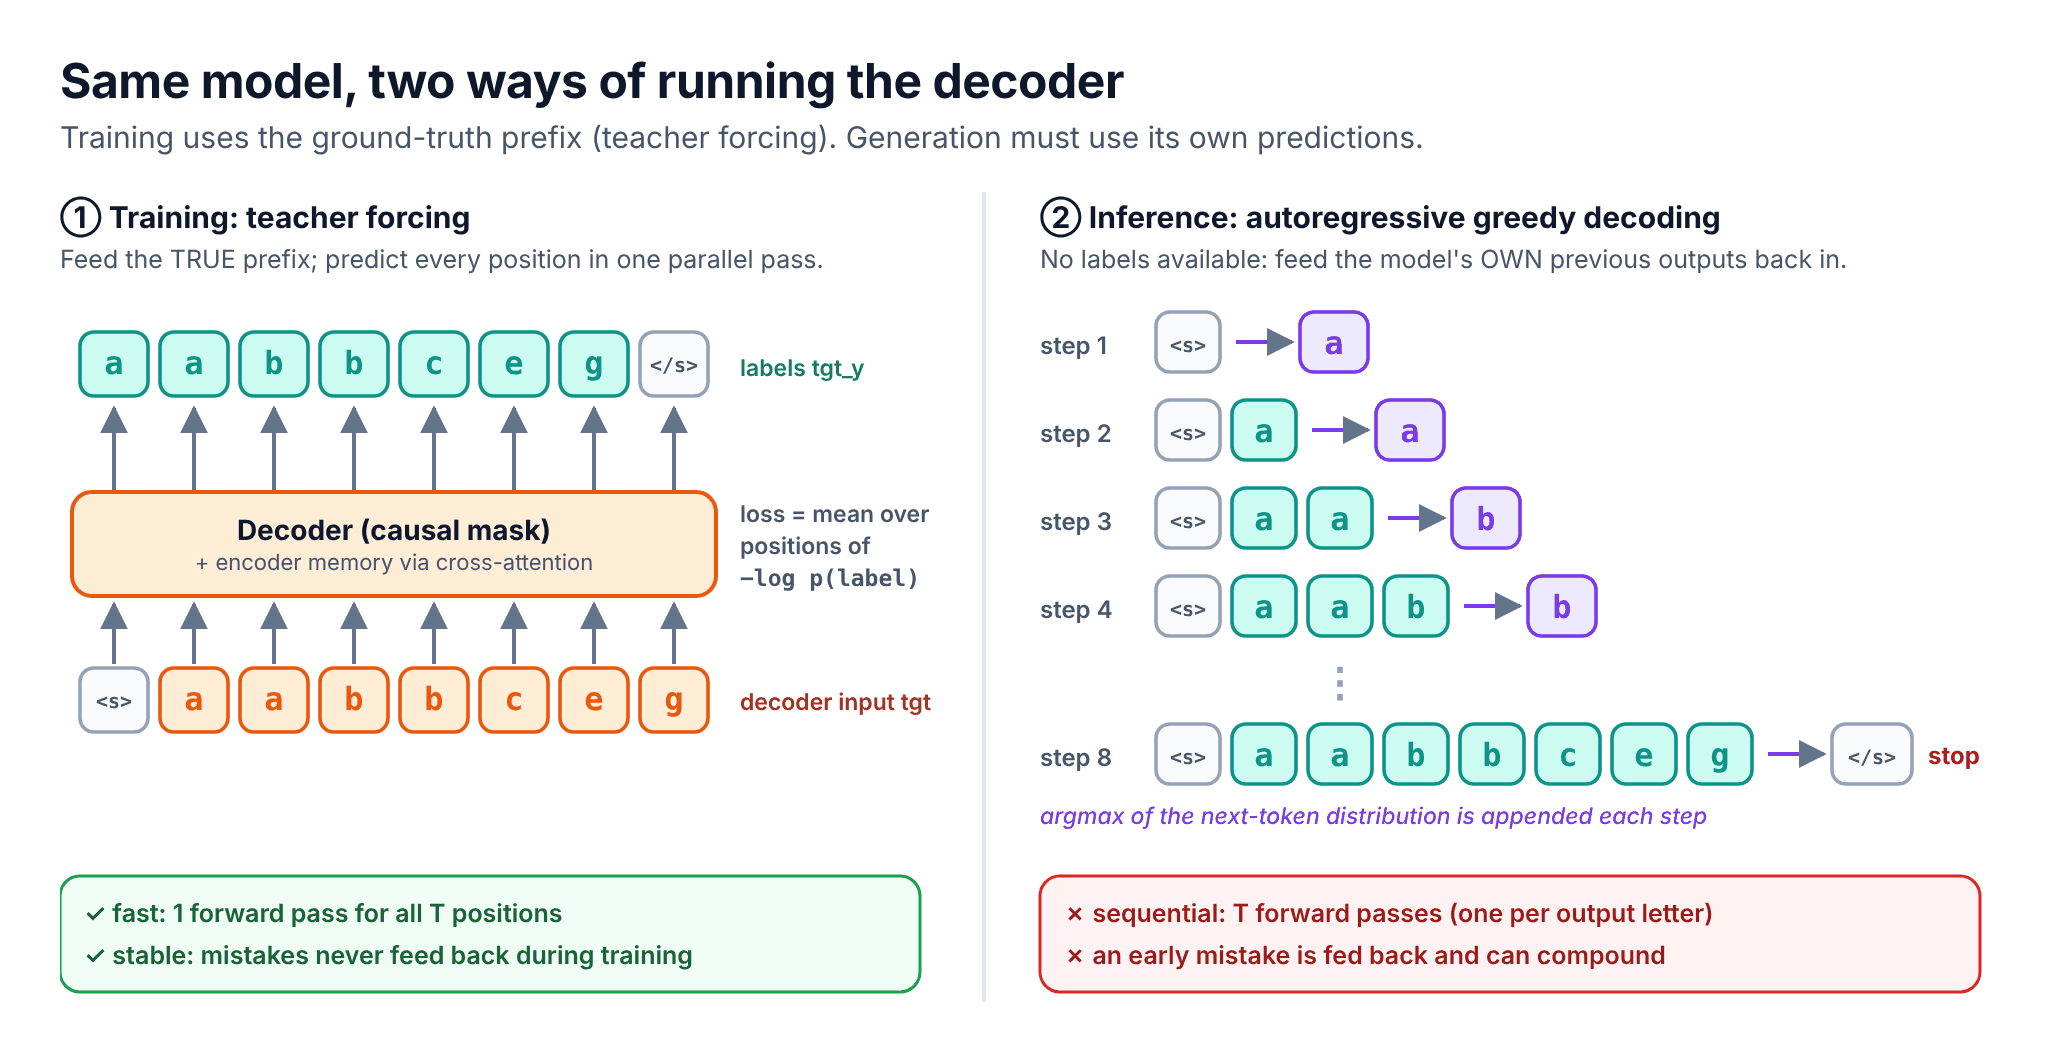</p>

### 6.1 Loss and learning-rate schedule

**Loss.** Maximise the probability of every correct next token, i.e. minimise the cross-entropy over real (non-pad) positions:

$$\mathcal{L} = -\frac{1}{\#\text{tokens}}\sum_{t}\log p_\theta\!\left(y_t \mid y_{<t},\, x\right)$$

Because the generator already outputs log-probabilities, this is `F.nll_loss(..., ignore_index=PAD)`.
📎 The Annotated Transformer also adds *label smoothing*; we don't need it for this task.

**Learning rate.** The Annotated Transformer uses Adam with *warm-up* followed by inverse-square-root decay (the "Noam" schedule):

$$\text{lr}(step) = \text{factor}\cdot d_{\text{model}}^{-0.5}\cdot\min\!\left(step^{-0.5},\; step\cdot \text{warmup}^{-1.5}\right)$$

Warm-up keeps early updates small while Adam's statistics are still unreliable.

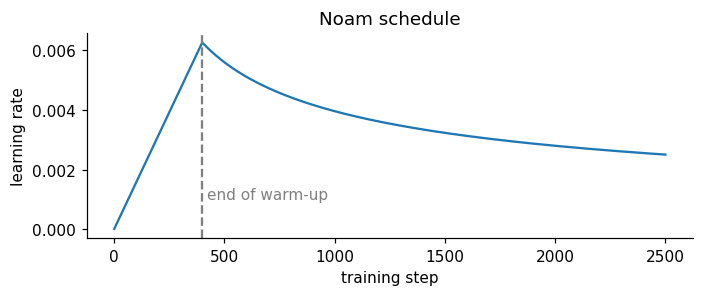

In [18]:
def rate(step: int, model_size: int, factor: float, warmup: int) -> float:
    # Noam learning-rate schedule from the Annotated Transformer.
    step = max(step, 1)        # avoid 0 ** -0.5
    return factor * model_size ** (-0.5) * min(step ** (-0.5), step * warmup ** (-1.5))


def loss_fn(log_probs, targets):
    # log_probs: (B, T, V)   targets: (B, T)   -> mean NLL over non-pad tokens
    return F.nll_loss(log_probs.reshape(-1, log_probs.size(-1)), targets.reshape(-1), ignore_index=PAD)


TRAIN_STEPS, BATCH_SIZE, WARMUP, LR_FACTOR = 2500, 128, 400, 1.0

steps = np.arange(1, TRAIN_STEPS + 1)
plt.figure(figsize=(6.5, 2.8))
plt.plot(steps, [rate(s, CONFIG["d_model"], LR_FACTOR, WARMUP) for s in steps])
plt.axvline(WARMUP, ls="--", c="gray"); plt.text(WARMUP * 1.05, 0.001, "end of warm-up", color="gray")
plt.xlabel("training step"); plt.ylabel("learning rate"); plt.title("Noam schedule")
plt.tight_layout(); plt.show()

### 6.2 Decoding and evaluation helpers
We need `greedy_decode` (📎 from the Annotated Transformer, extended to a whole batch and to stop at `</s>`) to measure **exact-match accuracy** on the validation set during training.

In [19]:
@torch.no_grad()
def greedy_decode(model, src, src_mask, max_len, start_symbol=BOS):
    # Generate one token at a time, always taking the most likely next token.
    memory = model.encode(src, src_mask)                          # encode the input ONCE
    ys = torch.full((src.size(0), 1), start_symbol, dtype=torch.long, device=src.device)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    for _ in range(max_len - 1):
        out = model.decode(memory, src_mask, ys, subsequent_mask(ys.size(1)).to(src.device))
        log_probs = model.generator(out[:, -1])                    # only the LAST position matters
        next_word = log_probs.argmax(dim=-1)
        next_word = next_word.masked_fill(finished, PAD)           # sequences that are done emit <pad>
        ys = torch.cat([ys, next_word[:, None]], dim=1)
        finished |= next_word == EOS
        if finished.all():
            break
    return ys                                                      # (B, <= max_len), starts with <s>


@torch.no_grad()
def predict(model, strings, stoi=STOI, itos=ITOS, batch_size=500):
    # Sort a list of strings with the model. Returns a list of predicted strings.
    model.eval()
    preds = []
    for i in range(0, len(strings), batch_size):
        src = to_tensor(strings[i : i + batch_size], stoi=stoi).to(device)
        ys = greedy_decode(model, src, (src != PAD).unsqueeze(-2), max_len=src.size(1) + 2)
        preds += [decode_ids(y, itos) for y in ys]
    return preds


def exact_match(model, data, **kw) -> float:
    preds = predict(model, [s for s, _ in data], **kw)
    return float(np.mean([p == t for p, (_, t) in zip(preds, data)]))

### 6.3 The training loop
A standard PyTorch loop. The only Transformer-specific parts are the `Batch` masks and the shifted targets.

In [20]:
def train(model, train_data, val_data, steps=TRAIN_STEPS, batch_size=BATCH_SIZE,
          warmup=WARMUP, factor=LR_FACTOR, eval_every=250, stoi=STOI, itos=ITOS):
    d_model = model.src_embed[0].d_model
    optimizer = torch.optim.Adam(model.parameters(), lr=1.0, betas=(0.9, 0.98), eps=1e-9)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: rate(s + 1, d_model, factor, warmup))

    history = {"step": [], "train_loss": [], "val_exact": []}
    rng = random.Random(0)
    order, pos, running = list(range(len(train_data))), len(train_data), []
    start = time.time()

    for step in range(1, steps + 1):
        if pos + batch_size > len(order):                  # new epoch: reshuffle
            rng.shuffle(order); pos = 0
        batch = make_batch([train_data[j] for j in order[pos : pos + batch_size]], stoi=stoi)
        pos += batch_size

        model.train()
        log_probs = model.generator(model(batch.src, batch.tgt, batch.src_mask, batch.tgt_mask))
        loss = loss_fn(log_probs, batch.tgt_y)             # teacher forcing: all positions at once

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        running.append(loss.item())

        if step % eval_every == 0 or step == steps:
            val_acc = exact_match(model, val_data, stoi=stoi, itos=itos)
            history["step"].append(step)
            history["train_loss"].append(float(np.mean(running))); running = []
            history["val_exact"].append(val_acc)
            print(f"step {step:5d} | loss {history['train_loss'][-1]:.4f} | "
                  f"val exact-match {100 * val_acc:5.1f}% | lr {scheduler.get_last_lr()[0]:.2e} | "
                  f"{time.time() - start:5.1f}s")
    return history

### 6.4 Train! 🚀

*While it trains:* what accuracy would a model get if it just copied the input unchanged?

In [21]:
set_seed(0)
model = make_model(VOCAB_SIZE, VOCAB_SIZE, **CONFIG).to(device)
history = train(model, train_data, val_data, steps=TRAIN_STEPS)

step   250 | loss 1.2396 | val exact-match  58.4% | lr 3.92e-03 |   8.0s
step   500 | loss 0.2686 | val exact-match  74.2% | lr 5.58e-03 |  15.1s
step   750 | loss 0.1776 | val exact-match  78.8% | lr 4.56e-03 |  22.6s
step  1000 | loss 0.1351 | val exact-match  91.3% | lr 3.95e-03 |  29.7s
step  1250 | loss 0.1086 | val exact-match  91.3% | lr 3.53e-03 |  37.4s
step  1500 | loss 0.0903 | val exact-match  92.9% | lr 3.23e-03 |  44.9s
step  1750 | loss 0.0805 | val exact-match  96.2% | lr 2.99e-03 |  55.1s
step  2000 | loss 0.0733 | val exact-match  97.3% | lr 2.79e-03 |  64.3s
step  2250 | loss 0.0664 | val exact-match  95.5% | lr 2.63e-03 |  74.2s
step  2500 | loss 0.0612 | val exact-match  98.4% | lr 2.50e-03 |  81.4s


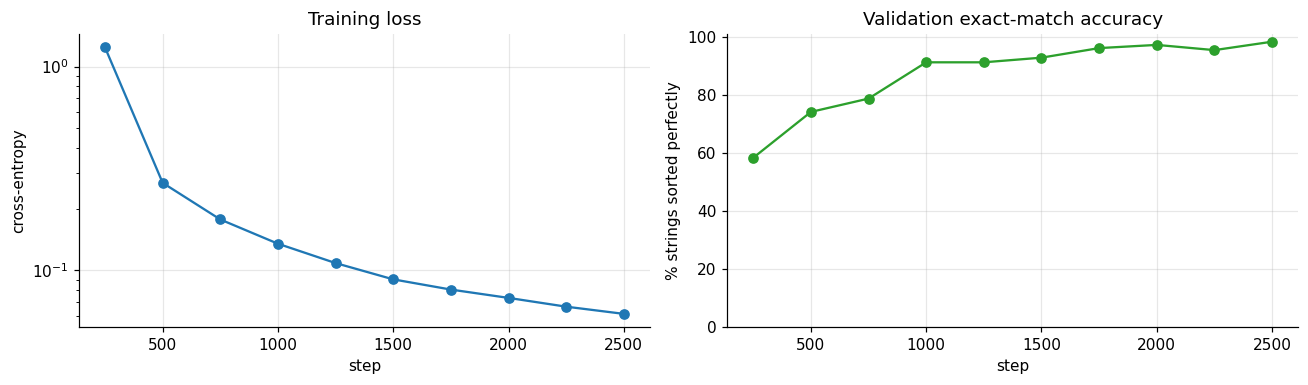

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
ax1.plot(history["step"], history["train_loss"], marker="o")
ax1.set(xlabel="step", ylabel="cross-entropy", title="Training loss", yscale="log")
ax2.plot(history["step"], [100 * a for a in history["val_exact"]], marker="o", color="tab:green")
ax2.set(xlabel="step", ylabel="% strings sorted perfectly", title="Validation exact-match accuracy", ylim=(0, 101))
for ax in (ax1, ax2): ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
# 7. Generate and evaluat

### 7.1 Try it on real words
The model was trained on *random* letter strings. Does it work on real words? ✍️ Add your own name to the list.

In [23]:
words = ["transformer", "attention", "princeton", "algorithms", "cabbage", "banana", "sorting"]   # <- add yours (3–12 letters)

for word, pred in zip(words, predict(model, words)):
    truth = key_indexed_counting(word)
    print(f"{word:>12s} -> {pred:<12s} {'✅' if pred == truth else '❌ expected ' + truth}")

 transformer -> aefmnorrrst  ✅
   attention -> aeinnottt    ✅
   princeton -> ceinnoprt    ✅
  algorithms -> aghilmorst   ✅
     cabbage -> aabbceg      ✅
      banana -> aaabnn       ✅
     sorting -> ginorst      ✅


### 7.2 Held-out test set
Two metrics:
* **exact match**: the whole string is perfectly sorted (strict),
* **error type**: when it is wrong, *how* is it wrong? Wrong length? Not in order? Right order but wrong letters?

In [24]:
def error_type(src: str, pred: str) -> str:
    if pred == key_indexed_counting(src):
        return "correct"
    if len(pred) != len(src):
        return "wrong length"
    if list(pred) != sorted(pred):
        return "not sorted"
    return "wrong letters"            # sorted and right length, but not the input's letters

test_src = [s for s, _ in test_data]
test_pred = predict(model, test_src)
types = [error_type(s, p) for s, p in zip(test_src, test_pred)]
print(f"Test exact-match accuracy: {100 * types.count('correct') / len(types):.2f}%")
for t in ["wrong length", "not sorted", "wrong letters"]:
    print(f"  {t:<14s}: {types.count(t)}")

print("\nSome mistakes (if any):")
for s, p, t in [(s, p, t) for s, p, t in zip(test_src, test_pred, types) if t != "correct"][:6]:
    print(f"  {s:<12s} pred={p:<13s} truth={key_indexed_counting(s):<13s} ({t})")

Test exact-match accuracy: 99.25%
  wrong length  : 15
  not sorted    : 0
  wrong letters : 0

Some mistakes (if any):
  tkflfkyltijz pred=ffijkklttyz   truth=ffijkkllttyz  (wrong length)
  fuaedtfopfb  pred=abdeffoptu    truth=abdefffoptu   (wrong length)
  dnylooizioj  pred=diijlnooyz    truth=diijlnoooyz   (wrong length)
  ajkk         pred=ajk           truth=ajkk          (wrong length)
  ikjjhajgj    pred=aghijjjjjk    truth=aghijjjjk     (wrong length)
  bcfyjhejyej  pred=bceefhjjyy    truth=bceefhjjjyy   (wrong length)


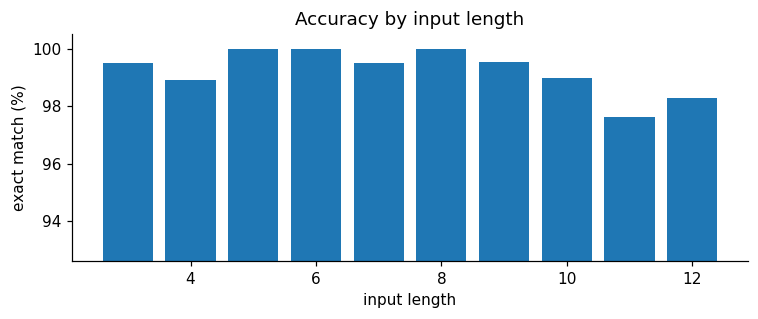

In [25]:
lengths = np.array([len(s) for s in test_src])
correct = np.array([t == "correct" for t in types])
Ls = list(range(MIN_LEN, MAX_LEN + 1))
acc_by_len = [100 * correct[lengths == L].mean() for L in Ls]

plt.figure(figsize=(7, 3))
plt.bar(Ls, acc_by_len, color="tab:blue")
plt.ylim(min(acc_by_len) - 5, 100.5)
plt.xlabel("input length"); plt.ylabel("exact match (%)"); plt.title("Accuracy by input length")
plt.tight_layout(); plt.show()

🧠 **Concept check.** Longer strings are harder. Why? *(Hint: each output letter is a chance to make a mistake, and with greedy decoding one mistake is fed back as input.)*

---
# 8. Looking inside: attention maps

Each `MultiHeadedAttention` module stores its last weights in `.attn` with shape `(B, heads, T_q, T_k)`. We run one forward pass and plot them.

**Cross-attention** is the most interesting: when the decoder writes the $t$-th sorted letter, which **input** positions does it look at?
White boxes mark the input positions that contain the letter being written.

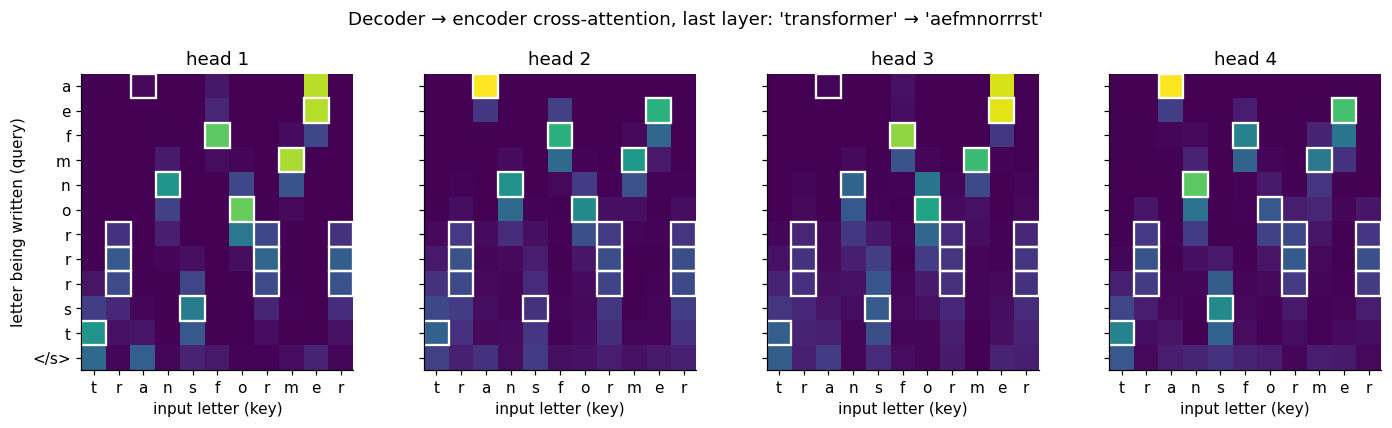

In [26]:
def attention_maps(model, word):
    # Teacher-forced pass on the model's own prediction; returns (pred, cross-attn, enc self-attn).
    pred = predict(model, [word])[0]
    model.eval()
    b = make_batch([(word, pred)])
    with torch.no_grad():
        model(b.src, b.tgt, b.src_mask, b.tgt_mask)
    cross = model.decoder.layers[-1].src_attn.attn[0].cpu()     # (h, T, S)
    enc = model.encoder.layers[-1].self_attn.attn[0].cpu()      # (h, S, S)
    return pred, cross, enc


def plot_cross_attention(model, word):
    pred, cross, _ = attention_maps(model, word)
    rows = list(pred) + ["</s>"]                                 # row t predicts this token
    h = cross.size(0)
    fig, axes = plt.subplots(1, h, figsize=(3.3 * h, 3.6), sharey=True)
    for k, ax in enumerate(axes):
        ax.imshow(cross[k], cmap="viridis", vmin=0, vmax=1)
        ax.set_xticks(range(len(word)), list(word)); ax.set_yticks(range(len(rows)), rows)
        ax.set_title(f"head {k + 1}"); ax.set_xlabel("input letter (key)")
        for r, out_ch in enumerate(rows):                       # outline where the written letter lives
            for c, in_ch in enumerate(word):
                if in_ch == out_ch:
                    ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fill=False, ec="white", lw=1.5))
    axes[0].set_ylabel("letter being written (query)")
    fig.suptitle(f"Decoder → encoder cross-attention, last layer: '{word}' → '{pred}'", y=1.02)
    plt.tight_layout(); plt.show()

plot_cross_attention(model, "transformer")

🧠 **Discussion**
* Does at least one head put most of its weight on the input position(s) holding the letter being written? That is a learned "find the next letter" lookup.
* For repeated letters (the three `r`s) does the model attend to *all* copies, or one at a time? How could it know how many copies remain?
* Are the heads redundant, or do they look different from one another?

Below is **encoder self-attention**: how input letters look at each other before decoding begins.

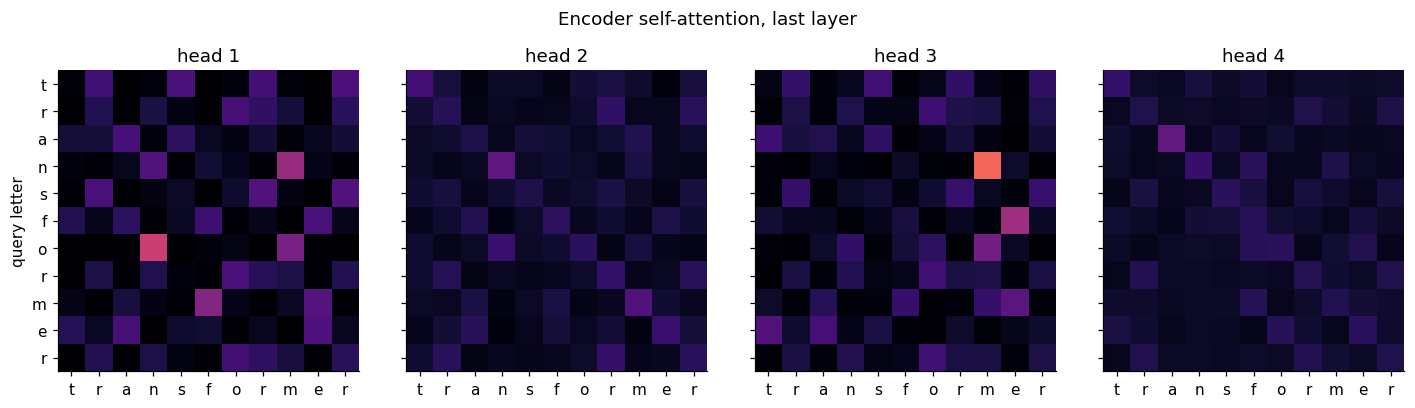

In [27]:
_, _, enc = attention_maps(model, "transformer")
word = "transformer"
fig, axes = plt.subplots(1, enc.size(0), figsize=(3.3 * enc.size(0), 3.4), sharey=True)
for k, ax in enumerate(axes):
    ax.imshow(enc[k], cmap="magma", vmin=0, vmax=1)
    ax.set_xticks(range(len(word)), list(word)); ax.set_yticks(range(len(word)), list(word))
    ax.set_title(f"head {k + 1}")
axes[0].set_ylabel("query letter"); fig.suptitle("Encoder self-attention, last layer", y=1.02)
plt.tight_layout(); plt.show()

⚠️ **Caution.** Attention maps are a useful diagnostic, but they are not a complete explanation of the model's computation: values, residual paths and the FFN layers matter too.

---
# 9. Wrap-up

> A Transformer alternates **attention** (positions exchange information) with **position-wise computation** (each position is processed on its own).
> **Positional encodings** inject order, **masks** control who may look at whom, and the **decoder** generates autoregressively,
> trained in parallel with **teacher forcing**.

| Concept | Where in the code |
|---|---|
| Scaled dot-product attention | `attention` |
| Multi-head attention | `MultiHeadedAttention` |
| Positional information | `PositionalEncoding` |
| Residual + LayerNorm | `SublayerConnection` |
| Padding / causal masks | `Batch.src_mask`, `Batch.make_std_mask`, `subsequent_mask` |
| Teacher forcing | `Batch.tgt` / `Batch.tgt_y`, `train` |
| Autoregressive generation | `greedy_decode` |

---
# [OPTIONAL] Self-study and homework

| | Experiment | Question |
|---|---|---|
| **A** | Compare with `torch.nn.Transformer` | What does the library hide? |
| **B** | Length generalisation | Does it sort strings *longer* than any it trained on? |
| **C** | Remove positional encoding from the encoder | Is order information needed to sort? |
| **D** | Sort a *list of words* (true algs4 string sort) | Can it compare multi-character keys? |
| **E** | Architecture sweeps | What actually matters: heads, depth, width, data? |

## [OPTIONAL] A. The same model with `torch.nn.Transformer`

PyTorch ships the whole encoder–decoder stack. We wrap it so it exposes the **same interface** (`encode`, `decode`, `generator`) and reuses our `train` and `greedy_decode` unchanged.
Note the mask convention flips: PyTorch masks use **`True` = blocked**.

In [28]:
import warnings
warnings.filterwarnings("ignore", message=".*enable_nested_tensor.*")

class TorchSortTransformer(nn.Module):
    def __init__(self, vocab, N=2, d_model=64, d_ff=128, h=4, dropout=0.1):
        super().__init__()
        self.src_embed = nn.Sequential(Embeddings(d_model, vocab), PositionalEncoding(d_model, dropout))
        self.tgt_embed = nn.Sequential(Embeddings(d_model, vocab), PositionalEncoding(d_model, dropout))
        self.tf = nn.Transformer(d_model, h, N, N, d_ff, dropout, batch_first=True, norm_first=True)
        self.generator = Generator(d_model, vocab)

    def encode(self, src, src_mask):
        return self.tf.encoder(self.src_embed(src), src_key_padding_mask=~src_mask[:, 0, :])

    def decode(self, memory, src_mask, tgt, tgt_mask):
        causal = ~subsequent_mask(tgt.size(1))[0].to(tgt.device)          # True = blocked
        return self.tf.decoder(self.tgt_embed(tgt), memory, tgt_mask=causal,
                               tgt_key_padding_mask=(tgt == PAD),
                               memory_key_padding_mask=~src_mask[:, 0, :])

    def forward(self, src, tgt, src_mask, tgt_mask):
        return self.decode(self.encode(src, src_mask), src_mask, tgt, tgt_mask)


torch_model = TorchSortTransformer(VOCAB_SIZE).to(device)
print(f"ours           : {sum(p.numel() for p in model.parameters()):,} parameters")
print(f"nn.Transformer : {sum(p.numel() for p in torch_model.parameters()):,} parameters")
# torch_history = train(torch_model, train_data, val_data)   # uncomment to train it the same way

ours           : 173,277 parameters
nn.Transformer : 173,277 parameters


The parameter counts match **exactly**: same embeddings, same pre-norm layers, same final norms. Our ~150 lines of code *are* `nn.Transformer`.

✍️ **Exercise.** Uncomment the training line and compare training speed. PyTorch's version uses fused attention kernels. Does it reach the same accuracy?

## [OPTIONAL] B. Length generalisation
The model was trained on lengths 3–12, and its positional encodings support up to 64. What happens at lengths 13–20?

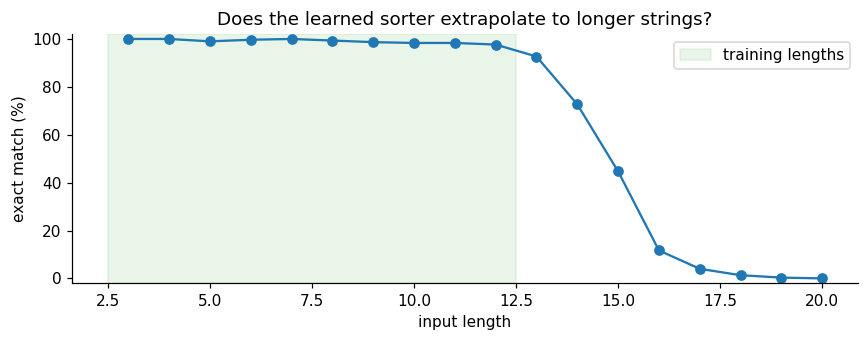

In [29]:
gen_lengths = list(range(MIN_LEN, 21))
gen_acc = []
for L in gen_lengths:
    data_L = make_dataset(300, seed=100 + L, min_len=L, max_len=L)
    gen_acc.append(100 * exact_match(model, data_L))

plt.figure(figsize=(8, 3.2))
plt.axvspan(MIN_LEN - 0.5, MAX_LEN + 0.5, color="tab:green", alpha=0.1, label="training lengths")
plt.plot(gen_lengths, gen_acc, marker="o")
plt.xlabel("input length"); plt.ylabel("exact match (%)"); plt.ylim(-2, 102)
plt.title("Does the learned sorter extrapolate to longer strings?"); plt.legend()
plt.tight_layout(); plt.show()

Failure here is a useful result: fitting a function on a finite training distribution does **not** guarantee the *algorithmic* generalisation that key-indexed counting has for free.
How might you fix it? *(More lengths in training? Relative position encodings? Remove encoder positions? See C.)*

## [OPTIONAL] C. Do we need positional encoding in the encoder?
Sorting depends only on *which* letters appear, not *where*. Train a model **without** encoder positional encodings and compare.
We also test **permutation consistency**: does shuffling the input change the model's answer?

In [30]:
set_seed(0)
model_no_pe = make_model(VOCAB_SIZE, VOCAB_SIZE, **CONFIG, src_positions=False).to(device)
history_no_pe = train(model_no_pe, train_data, val_data, eval_every=500)

def permutation_consistency(model, n=300, seed=0):
    rng = random.Random(seed)
    words = [s for s, _ in test_data[:n]]
    shuffled = ["".join(rng.sample(w, len(w))) for w in words]
    return np.mean([a == b for a, b in zip(predict(model, words), predict(model, shuffled))])

for name, m in [("with encoder PE", model), ("without encoder PE", model_no_pe)]:
    print(f"{name:<20s} test exact-match {100 * exact_match(m, test_data):5.1f}% | "
          f"same answer after shuffling input {100 * permutation_consistency(m):5.1f}%")

step   500 | loss 0.7692 | val exact-match  58.6% | lr 5.58e-03 |  14.5s
step  1000 | loss 0.2072 | val exact-match  79.7% | lr 3.95e-03 |  33.0s
step  1500 | loss 0.1529 | val exact-match  86.6% | lr 3.23e-03 |  50.6s
step  2000 | loss 0.1283 | val exact-match  84.8% | lr 2.79e-03 |  66.9s
step  2500 | loss 0.1122 | val exact-match  89.7% | lr 2.50e-03 |  83.7s
with encoder PE      test exact-match  99.2% | same answer after shuffling input  99.0%
without encoder PE   test exact-match  91.6% | same answer after shuffling input 100.0%


## [OPTIONAL] D. Sorting a list of words (LSD-style string sort)
algs4's string sorts sort **arrays of strings**, e.g. license plates or words. Here the input is several 3-letter words separated by spaces, and the output is the words in sorted order:
`"dab cab fad bad"` → `"bad cab dab fad"`.

The model must now compare **multi-character keys**: first letter, then second letter on ties, and so on, exactly like LSD/MSD radix sort.
Only the data generator and vocabulary change; the model and training code are reused.

In [31]:
WORD_LEN, MIN_WORDS, MAX_WORDS = 3, 2, 5
WORD_ALPHABET = "abcdefgh"                         # small alphabet -> many shared prefixes (harder!)
W_ITOS = SPECIALS + list(WORD_ALPHABET) + [" "]
W_STOI = {t: i for i, t in enumerate(W_ITOS)}

def lsd_sort(words, W=WORD_LEN, alphabet=WORD_ALPHABET):
    # LSD radix sort (algs4 §5.1): stable key-indexed counting on each character, right to left.
    index = {ch: r for r, ch in enumerate(alphabet)}
    a = list(words)
    for d in reversed(range(W)):
        count = [0] * (len(alphabet) + 1)
        for w in a: count[index[w[d]] + 1] += 1
        for r in range(len(alphabet)): count[r + 1] += count[r]
        aux = [None] * len(a)
        for w in a:
            aux[count[index[w[d]]]] = w; count[index[w[d]]] += 1
        a = aux
    return a

def make_word_dataset(n, seed):
    rng = random.Random(seed)
    data = []
    for _ in range(n):
        words = ["".join(rng.choice(WORD_ALPHABET) for _ in range(WORD_LEN)) for _ in range(rng.randint(MIN_WORDS, MAX_WORDS))]
        data.append((" ".join(words), " ".join(lsd_sort(words))))
    return data

word_train, word_val = make_word_dataset(50_000, seed=11), make_word_dataset(500, seed=12)
for s, t in word_train[:4]:
    print(f"{s:<22s} -> {t}")
assert all(t.split() == sorted(s.split()) for s, t in word_train[:1000])

hhd chc bhe cba ghc    -> bhe cba chc ghc hhd
baa dda                -> baa dda
fhd deh abh egb efd    -> abh deh efd egb fhd
abb gbe gba add        -> abb add gba gbe


In [32]:
# Uses more steps than the main task: comparing whole words is harder than comparing single letters.
set_seed(0)
word_model = make_model(len(W_ITOS), len(W_ITOS), **CONFIG).to(device)
word_history = train(word_model, word_train, word_val, steps=4000, eval_every=500, stoi=W_STOI, itos=W_ITOS)

samples = ["dab cab fad bad", "hhh aaa hha", "bed bad bee ace"]
for s, p in zip(samples, predict(word_model, samples, stoi=W_STOI, itos=W_ITOS)):
    print(f"{s:<18s} -> {p:<18s} {'✅' if p.split() == sorted(s.split()) else '❌'}")

step   500 | loss 1.2367 | val exact-match  11.0% | lr 5.58e-03 |  18.2s
step  1000 | loss 0.2763 | val exact-match  83.0% | lr 3.95e-03 |  38.1s
step  1500 | loss 0.1036 | val exact-match  96.0% | lr 3.23e-03 |  59.5s
step  2000 | loss 0.0656 | val exact-match  98.8% | lr 2.79e-03 |  86.5s
step  2500 | loss 0.0515 | val exact-match  99.2% | lr 2.50e-03 | 108.0s
step  3000 | loss 0.0423 | val exact-match  99.4% | lr 2.28e-03 | 124.1s
step  3500 | loss 0.0352 | val exact-match  98.6% | lr 2.11e-03 | 139.5s
step  4000 | loss 0.0286 | val exact-match  99.4% | lr 1.98e-03 | 156.3s
dab cab fad bad    -> bad cab dab fad    ✅
hhh aaa hha        -> aaa hha hhh        ✅
bed bad bee ace    -> ace bad bee bed    ❌


✍️ Try a larger `d_model`, more layers, or more steps. Is the difficulty in *comparing* words, or in *copying* them intact?

## [OPTIONAL] E. Architecture experiments
Change **one** setting at a time in `CONFIG`, retrain (`TRAIN_STEPS = 1500` is enough to compare), and record the test exact-match:

| setting | values to try |
|---|---|
| `h` (heads) | 1, 2, 4, 8 |
| `N` (layers) | 1, 2, 3 |
| `d_model` | 32, 64, 128 |
| `d_ff` | 64, 128, 256 |
| `dropout` | 0.0, 0.1, 0.3 |
| training set size | 5 000, 20 000, 50 000 |

Questions: Does one head suffice? Does depth help more than width? How little data is enough?

In [33]:
def run_experiment(steps=1500, n_train=50_000, **overrides):
    cfg = {**CONFIG, **overrides}
    set_seed(0)
    m = make_model(VOCAB_SIZE, VOCAB_SIZE, **cfg).to(device)
    train(m, train_data[:n_train], val_data, steps=steps, eval_every=steps)
    return exact_match(m, test_data)

# Example (uncomment):
# for h in [1, 2, 4]:
#     print(f"h={h}: test exact-match = {100 * run_experiment(h=h):.1f}%")